# Neural value-gradient solver

A bounded one-asset FBSNN experiment under the constant-parameter risk-neutral GBM model. A smooth value network is fitted with local discounted BSDE consistency and terminal payoff matching. Automatic differentiation supplies spot deltas and hence Brownian controls.

The notebook loads a saved run and evaluates it without retraining. Generate the default run from the repository root with:

```bash
python -m bsde_pricing train --run-dir scratch/runs/vanilla_fbsnn
```

Existing run directories are protected. The [methodology](../docs/methodology.md#first-value-gradient-training-experiment) defines the objective, streams, budgets and limits of this first experiment.

In [118]:
from pathlib import Path
import html
import json
import os
import platform

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from IPython.display import HTML, display

cwd = Path.cwd()
root = next((p for p in (cwd, cwd.parent) if (p / "bsde_pricing").is_dir()), None)
if root is None:
    raise RuntimeError("Open the deep-bsde-pricing repository folder before running the notebook.")
os.chdir(root)
from bsde_pricing.training import FBSNNSolver

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

def table(headers, rows):
    heading = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(format(v, '.7g') if isinstance(v, (float, np.floating)) else str(v))}</td>"
        for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

table(["Notebook runtime", "Version"], [("Python", platform.python_version()),
      ("NumPy", np.__version__), ("PyTorch", str(torch.__version__)),
      ("Matplotlib", matplotlib.__version__), ("System", platform.platform())])

Notebook runtime,Version
Python,3.12.16
NumPy,2.5.4
PyTorch,2.15.0
Matplotlib,3.11.2
System,macOS-27.0.1-arm64-arm-64bit


## 1. Saved experiment and financial scope

The network represents $V_\theta(t,S)$ and supplies $\Delta_\theta=\partial_S V_\theta$, with $Z_\theta=\sigma S\Delta_\theta$. Its physical-input normalisation is part of the graph. Training starts every path at the one specified spot and uses a fixed model and contract. It does not establish accuracy for different initial spots, model parameters or arbitrary states outside the sampled distribution.

The original recorded checkpoint is the last completed update. Current `train` runs save a validation-selected model as specified in section 8; the original version 1 file is retained for the results above. Monitoring paths are fixed, training paths are fresh at each update, and the post-training evaluation stream is separate. Monitoring did not select the original checkpoint. The targets are initial price error at most 0.25 currency units and delta error at most 0.02; a missed target remains visible.

In [119]:
run_dir = root / "scratch/runs/vanilla_fbsnn"
if not (run_dir / "model.pt").exists():
    raise FileNotFoundError("Create the saved run with: python -m bsde_pricing train --run-dir scratch/runs/vanilla_fbsnn")
report = json.loads((run_dir / "report.json").read_text())
solver = FBSNNSolver.load(run_dir / "model.pt")
history = report["history"]
config = report["config"]
initial = report["evaluation"]["initial"]
table(["Run setting", "Value"], [("Status", report["status"]),
      ("Completed updates", report["completed_updates"]), ("Time intervals", config["n_steps"]),
      ("Paths per update", config["batch_size"]), ("Hidden width", config["width"]),
      ("Parameters", sum(p.numel() for p in solver.network.parameters())),
      ("Seed", config["seed"]), ("Device / dtype", f"{report['device']} / {report['dtype']}"),
      ("Training seconds", report["training_seconds"]),
      ("Training runtime", f"Python {report['python']}, PyTorch {report['torch']}, {report['system']}")])
table(["Initial quantity", "Learned", "Analytical", "Signed error", "Target met"],
      [("Price", initial["price"], initial["reference_price"], initial["price_error"], report["targets_met"]["price"]),
       ("Delta", initial["delta"], initial["reference_delta"], initial["delta_error"], report["targets_met"]["delta"])])

Run setting,Value
Status,completed
Completed updates,3000
Time intervals,16
Paths per update,128
Hidden width,16
Parameters,337
Seed,2026
Device / dtype,cpu / torch.float64
Training seconds,6.205937
Training runtime,"Python 3.12.16, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit"


Initial quantity,Learned,Analytical,Signed error,Target met
Price,9.562298,9.413403,0.1488942,True
Delta,0.5160792,0.5987063,-0.08262714,False


## 2. Objective during optimisation

The dimensionless loss is the path-average sum of squared discounted local residuals divided by strike squared, plus the separately normalised terminal error. The training curve averages pre-update losses over each logging window; monitoring losses evaluate the updated model on one fixed path sample.

The dashed analytical local loss uses the same monitoring paths. It is a discretisation comparison, not a lower bound on the discrete objective. A network can trade local residuals against terminal fit, and lower loss does not by itself establish more accurate price or delta.

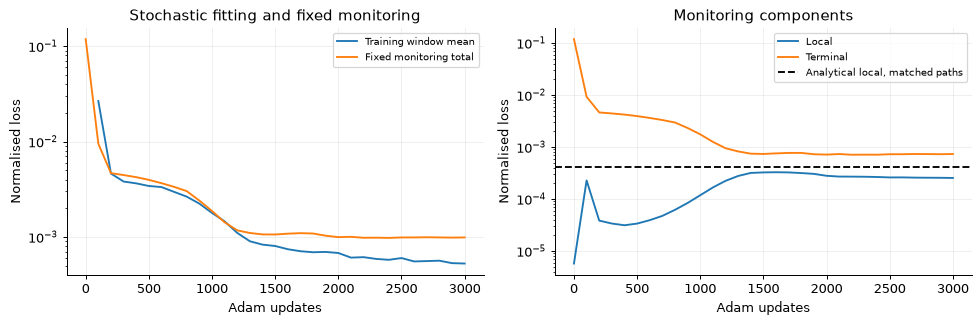

In [120]:
steps = np.array([h["step"] for h in history])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
logged_training = [h for h in history if h["training_loss_window_mean"] is not None]
axes[0].semilogy([h["step"] for h in logged_training],
                 [h["training_loss_window_mean"] for h in logged_training], label="Training window mean")
axes[0].semilogy(steps, [h["validation_total"] for h in history], label="Fixed monitoring total")
axes[1].semilogy(steps, [h["validation_local"] for h in history], label="Local")
axes[1].semilogy(steps, [h["validation_terminal"] for h in history], label="Terminal")
axes[1].axhline(report["validation_analytical_local_loss"], linestyle="--", color="black",
                label="Analytical local, matched paths")
for ax in axes:
    ax.set_xlabel("Adam updates")
    ax.set_ylabel("Normalised loss")
    ax.legend(fontsize=8)
axes[0].set_title("Stochastic fitting and fixed monitoring")
axes[1].set_title("Monitoring components")
fig.tight_layout()
plt.show()

## 3. Initial price and delta errors

These errors compare the deterministic network output and its input derivative at $(0,S_0)$ with Black-Scholes. They have no Monte Carlo standard error for a fixed trained model. Seed variability is a separate experiment. Signed symlog axes show the full trajectory, including the untrained model, while keeping the target bands visible.

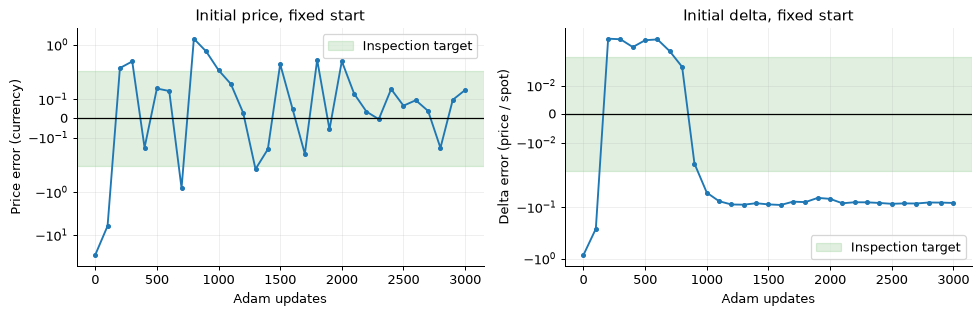

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, field, target, label in zip(axes, ("price_error", "delta_error"), (0.25, 0.02),
                                   ("Price error (currency)", "Delta error (price / spot)")):
    ax.plot(steps, [h[field] for h in history], "o-", markersize=3)
    ax.axhline(0, color="black", linewidth=1)
    ax.axhspan(-target, target, color="green", alpha=0.12, label="Inspection target")
    ax.set_yscale("symlog", linthresh=target)
    ax.set_xlabel("Adam updates")
    ax.set_ylabel(label)
    ax.legend()
axes[0].set_title("Initial price, fixed start")
axes[1].set_title("Initial delta, fixed start")
fig.tight_layout()
plt.show()

## 4. Fresh-path evaluation

The saved report contains the post-training evaluation using SeedSequence child 2. The additional sample below uses an explicit new seed and branch 3 for descriptive plots; it is not used for fitting or checkpoint selection. Errors are measured at pre-expiry grid points on the fixed-start path distribution. Terminal value error is reported separately, and terminal deltas are excluded.

Standard errors for mean signed errors use independent path averages, accounting for dependence across time within a path. They describe evaluation sampling uncertainty for this fixed model, not uncertainty from optimisation or the training seed.

In [122]:
plot_paths = 512
plot_seed = 2027
evaluation = solver.evaluate(n_paths=plot_paths, seed=plot_seed)
summary = evaluation.summary
table(["Measure", "Saved evaluation", "Fresh plotting sample"],
      [("Paths", report["evaluation"]["n_paths"], summary["n_paths"]),
       ("Pre-expiry price RMSE", report["evaluation"]["price_rmse_before_expiry"], summary["price_rmse_before_expiry"]),
       ("Pre-expiry delta RMSE", report["evaluation"]["delta_rmse_before_expiry"], summary["delta_rmse_before_expiry"]),
       ("Terminal payoff RMSE", report["evaluation"]["terminal_payoff_rmse"], summary["terminal_payoff_rmse"]),
       ("Local loss", report["evaluation"]["local_loss"], summary["local_loss"]),
       ("Analytical local loss, matched paths", report["evaluation"]["analytical_local_loss"], summary["analytical_local_loss"])])
table(["Fresh mean signed error", "Estimate", "Path-level SE"],
      [("Price", summary["mean_price_error"], summary["mean_price_error_se"]),
       ("Delta", summary["mean_delta_error"], summary["mean_delta_error_se"])])

Measure,Saved evaluation,Fresh plotting sample
Paths,2048,512
Pre-expiry price RMSE,0.9222957,0.9037401
Pre-expiry delta RMSE,0.1162418,0.1169896
Terminal payoff RMSE,1.755475,1.720026
Local loss,0.0002490521,0.0002474045
"Analytical local loss, matched paths",0.000395916,0.0004216958


Fresh mean signed error,Estimate,Path-level SE
Price,0.1086616,0.02537321
Delta,-0.008816053,0.003427173


## 5. Representative trajectories

The first three generated paths are retained without selection by prediction quality. Solid value curves show the learned model; dashed curves show the analytical reference on the same states.

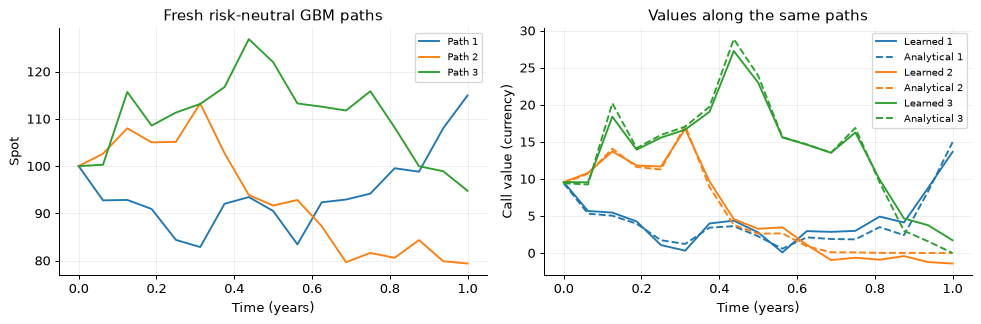

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for k in range(3):
    line, = axes[0].plot(evaluation.times, evaluation.spots[k], label=f"Path {k+1}")
    axes[1].plot(evaluation.times, evaluation.values[k], color=line.get_color(), label=f"Learned {k+1}")
    axes[1].plot(evaluation.times, evaluation.reference_values[k], "--", color=line.get_color(), label=f"Analytical {k+1}")
axes[0].set_ylabel("Spot")
axes[1].set_ylabel("Call value (currency)")
for ax in axes:
    ax.set_xlabel("Time (years)")
    ax.legend(fontsize=8)
axes[0].set_title("Fresh risk-neutral GBM paths")
axes[1].set_title("Values along the same paths")
fig.tight_layout()
plt.show()

## 6. Conditional state slices

Each column uses a selected interior time on the existing grid. Curves connect sorted sampled states; no new initial-spot training problem is introduced. The displayed ranges reflect the fresh path sample. The comparison can reveal slope errors even where prices appear close.

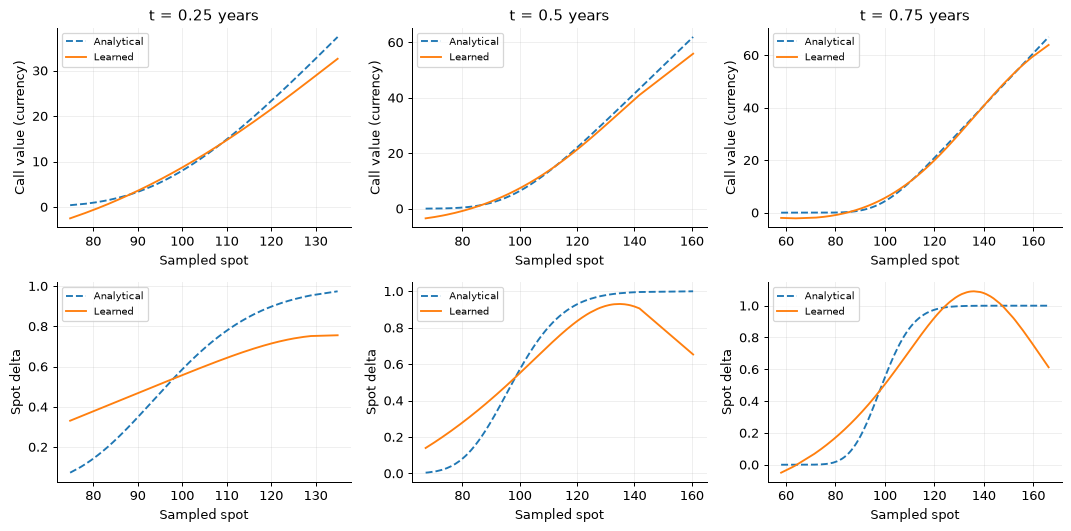

In [124]:
indices = sorted(set(max(1, min(config["n_steps"]-1, round(config["n_steps"]*fraction)))
                     for fraction in (0.25, 0.5, 0.75)))
fig, axes = plt.subplots(2, len(indices), figsize=(4*len(indices), 6), squeeze=False)
for column, index in enumerate(indices):
    order = np.argsort(evaluation.spots[:, index])
    sample_spots = evaluation.spots[order, index]
    axes[0, column].plot(sample_spots, evaluation.reference_values[order, index], "--", label="Analytical")
    axes[0, column].plot(sample_spots, evaluation.values[order, index], label="Learned")
    axes[1, column].plot(sample_spots, evaluation.reference_deltas[order, index], "--", label="Analytical")
    axes[1, column].plot(sample_spots, evaluation.deltas[order, index], label="Learned")
    axes[0, column].set_title(f"t = {evaluation.times[index]:.3g} years")
    axes[0, column].set_ylabel("Call value (currency)")
    axes[1, column].set_ylabel("Spot delta")
    for row in range(2):
        axes[row, column].set_xlabel("Sampled spot")
        axes[row, column].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Terminal payoff fit

The call payoff has a kink, while the tanh value network is smooth. The fit near strike and in sampled tails is visible below. This experiment does not yet separate network approximation, optimisation and grid bias; the observed errors are retained before any controlled follow-up experiment.

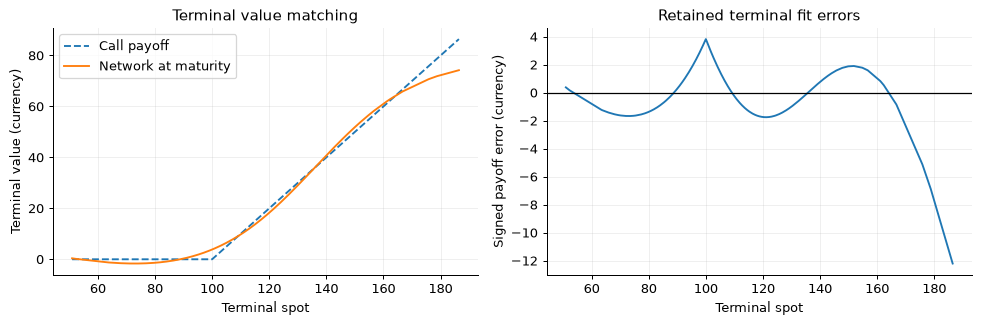

In [125]:
order = np.argsort(evaluation.spots[:, -1])
terminal_spots = evaluation.spots[order, -1]
terminal_errors = evaluation.values[order, -1]-evaluation.reference_values[order, -1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(terminal_spots, evaluation.reference_values[order, -1], "--", label="Call payoff")
axes[0].plot(terminal_spots, evaluation.values[order, -1], label="Network at maturity")
axes[0].set_ylabel("Terminal value (currency)")
axes[0].legend()
axes[1].plot(terminal_spots, terminal_errors)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("Signed payoff error (currency)")
for ax in axes:
    ax.set_xlabel("Terminal spot")
axes[0].set_title("Terminal value matching")
axes[1].set_title("Retained terminal fit errors")
fig.tight_layout()
plt.show()

## Interpretation

- Training and monitoring losses describe the discrete objective. Price and delta errors assess different quantities against an independent reference.
- The last completed update is retained even if an earlier monitoring point had a smaller error. Inspection targets are reported without extending the run until they pass.
- Fresh-path metrics are conditional on this model, contract, fixed start and time grid. They do not establish performance over all spots or model parameters.
- A single training seed does not measure optimisation variability. Checkpoint selection, seed comparisons and exact optimiser continuation are assessed in the sections below.

## 8. Seed variation and terminal-loss weighting

The first experiment remains above, including its missed delta target. The comparison below holds its architecture, path budget, time grid and learning-rate schedule fixed. Seeds **2026, 2027 and 2028** each run with terminal-loss weights **1 and 5**. Weight 5 is a single declared perturbation, not the outcome of a search. Each pair starts from identical network weights and uses identical training, validation and evaluation paths.

For each run, checkpoint selection minimises the **weighted validation objective** over the scheduled checks. No analytical price, delta or held-out metric enters selection. Both the selected checkpoint and the final update are evaluated on the same fresh paths. Early stopping is disabled in this fixed-budget comparison. Three seeds describe variability; they do not establish a reliable tail probability or a universal preferred weight.

Generate the study once from the repository root. Existing directories are protected:

```bash
python -m bsde_pricing training-study --run-dir scratch/runs/reproducibility
```

The notebook loads these files without training. Weighted total losses across different weights have different meanings, so the comparison uses physical errors and the common unweighted loss components.

The retained first-experiment outputs were recorded on the MacBook. The appended study table records the runtime for its results. Running all cells locally refreshes both sets from their saved files.

In [126]:
study_dir = root / "scratch/runs/reproducibility"
study = json.loads((study_dir / "study.json").read_text())
rows = study["runs"]
usable = [r for r in rows if r["status"] in ("completed", "time_budget_reached")]
table(["Study status", "Seeds", "Weights", "Failed runs", "Wall seconds"], [[
    study["status"], study["seeds"], study["terminal_weights"],
    sum(r["status"] == "failed" for r in rows), f'{study["wall_seconds"]:.3f}']])
table(["Seed", "Weight", "Status", "Updates", "Selected step", "Fit seconds", "Evaluation seconds"], [
    [r["seed"], r["terminal_weight"], r["status"], r.get("completed_updates", ""),
     r.get("selected_step", ""), f'{r.get("training_seconds", 0):.3f}' if "training_seconds" in r else "",
     f'{r.get("evaluation_seconds", 0):.3f}' if "evaluation_seconds" in r else r.get("error", "")]
    for r in rows])
reports = {r["directory"]: json.loads((study_dir / r["directory"] / "report.json").read_text()) for r in usable}
table(["Seed", "Weight", "Python", "NumPy", "PyTorch", "System"], [
    [r["seed"], r["terminal_weight"], reports[r["directory"]]["python"], reports[r["directory"]]["numpy"],
     reports[r["directory"]]["torch"], reports[r["directory"]]["system"]] for r in usable])

Study status,Seeds,Weights,Failed runs,Wall seconds
completed,"[2026, 2027, 2028]","[1, 5]",0,41.006


Seed,Weight,Status,Updates,Selected step,Fit seconds,Evaluation seconds
2026,1,completed,3000,2400,6.712,0.227
2026,5,completed,3000,1400,6.207,0.216
2027,1,completed,3000,3000,6.219,0.306
2027,5,completed,3000,3000,6.239,0.291
2028,1,completed,3000,3000,6.509,0.230
2028,5,completed,3000,2900,6.599,0.217


Seed,Weight,Python,NumPy,PyTorch,System
2026,1,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit
2026,5,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit
2027,1,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit
2027,5,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit
2028,1,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit
2028,5,3.12.16,2.5.4,2.15.0,macOS-27.0.1-arm64-arm-64bit


## 9. Initial price and delta across seeds

The shaded bands retain the original inspection targets: 0.25 price units and 0.02 delta. Checkpoint selection is based on the BSDE validation objective and need not minimise either error. The final-update results for seed 2026 and weight 1 provide the direct numerical check against the first experiment.

Seed,Weight,Checkpoint,Price error,Delta error,Terminal RMSE,Unweighted loss
2026,1,selected,+0.153759,-0.082716,1.837602,0.0005832
2026,1,last,+0.148894,-0.082627,1.755475,0.0005393
2026,5,selected,-0.196764,-0.109352,2.017263,0.0008090
2026,5,last,+0.231194,-0.086123,1.622910,0.0006618
2027,1,selected,+0.156187,-0.027648,1.252561,0.0003841
2027,1,last,+0.156187,-0.027648,1.252561,0.0003841
2027,5,selected,+0.258338,-0.058811,1.211835,0.0004215
2027,5,last,+0.258338,-0.058811,1.211835,0.0004215
2028,1,selected,-0.154162,+0.004470,1.459337,0.0004430
2028,1,last,-0.154162,+0.004470,1.459337,0.0004430


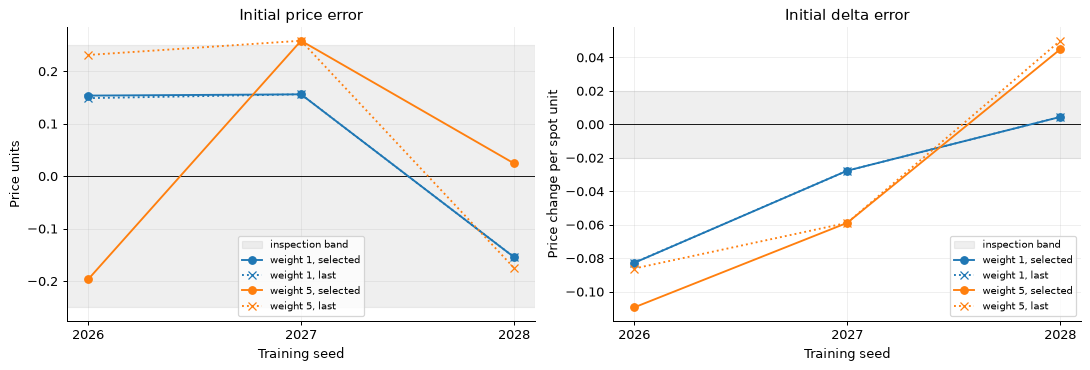

In [127]:
table(["Seed", "Weight", "Checkpoint", "Price error", "Delta error", "Terminal RMSE", "Unweighted loss"], [
    [r["seed"], r["terminal_weight"], checkpoint, f'{r[checkpoint]["price_error"]:+.6f}',
     f'{r[checkpoint]["delta_error"]:+.6f}', f'{r[checkpoint]["terminal_payoff_rmse"]:.6f}',
     f'{r[checkpoint]["unweighted_total_loss"]:.7f}']
    for r in usable for checkpoint in ("selected", "last")])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, tolerance, title in zip(axes, ("price_error", "delta_error"), (0.25, 0.02),
                                       ("Initial price error", "Initial delta error")):
    ax.axhspan(-tolerance, tolerance, color="grey", alpha=0.12, label="inspection band")
    ax.axhline(0, color="black", linewidth=0.7)
    for weight, color in zip(study["terminal_weights"], ("tab:blue", "tab:orange")):
        group = [r for r in usable if r["terminal_weight"] == weight]
        for checkpoint, marker, linestyle in (("selected", "o", "-"), ("last", "x", ":")):
            ax.plot([r["seed"] for r in group], [r[checkpoint][metric] for r in group],
                    marker=marker, linestyle=linestyle, color=color, label=f"weight {weight}, {checkpoint}")
    ax.set(title=title, xlabel="Training seed", xticks=study["seeds"])
    ax.legend(fontsize=8)
axes[0].set_ylabel("Price units")
axes[1].set_ylabel("Price change per spot unit")
plt.show()

## 10. Fresh-path errors and loss components

Terminal fit, price fit and delta fit answer different questions. Sample standard deviations below describe variation between three independently seeded runs. The two weights share streams within each seed. They are not six independent estimates of one configuration. The local and terminal losses are dimensionless; terminal RMSE is in price units.

Weight,Checkpoint,Complete / usable,Price error mean (sd),Delta error mean (sd),Terminal RMSE mean (sd),Fit seconds mean (sd)
1,selected,3 / 3,0.05193 (0.17848),-0.03530 (0.04409),1.51650 (0.29668),6.47979 (0.24750)
1,last,3 / 3,0.05031 (0.17711),-0.03527 (0.04405),1.48912 (0.25278),6.47979 (0.24750)
5,selected,3 / 3,0.02869 (0.22758),-0.04109 (0.07863),1.52509 (0.43149),6.34837 (0.21751)
5,last,3 / 3,0.10493 (0.24259),-0.03164 (0.07202),1.39306 (0.20981),6.34837 (0.21751)


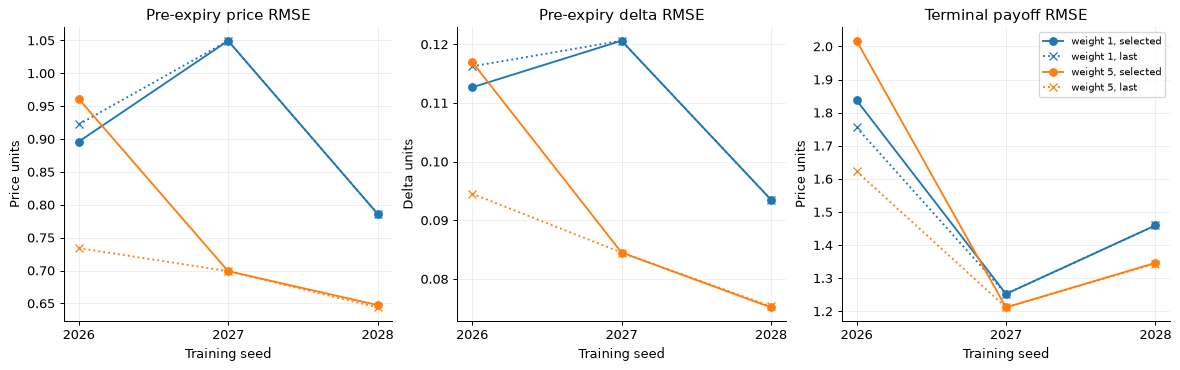

In [128]:
table(["Weight", "Checkpoint", "Complete / usable", "Price error mean (sd)", "Delta error mean (sd)",
       "Terminal RMSE mean (sd)", "Fit seconds mean (sd)"], [
    [s["terminal_weight"], s["checkpoint"], f'{s["completed_runs"]} / {s["usable_runs"]}',
     *[f'{s[k]["mean"]:.5f} ({s[k]["sample_std"]:.5f})' if s[k]["sample_std"] is not None
       else str(s[k]["mean"]) for k in ("price_error", "delta_error", "terminal_payoff_rmse", "training_seconds")]]
    for s in study["summary"]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, metric, title in zip(axes,
        ("price_rmse_before_expiry", "delta_rmse_before_expiry", "terminal_payoff_rmse"),
        ("Pre-expiry price RMSE", "Pre-expiry delta RMSE", "Terminal payoff RMSE")):
    for weight, color in zip(study["terminal_weights"], ("tab:blue", "tab:orange")):
        group = [r for r in usable if r["terminal_weight"] == weight]
        for checkpoint, marker, linestyle in (("selected", "o", "-"), ("last", "x", ":")):
            ax.plot([r["seed"] for r in group], [r[checkpoint][metric] for r in group],
                    marker=marker, linestyle=linestyle, color=color, label=f"weight {weight}, {checkpoint}")
    ax.set(title=title, xlabel="Training seed", xticks=study["seeds"])
axes[0].set_ylabel("Price units")
axes[1].set_ylabel("Delta units")
axes[2].set_ylabel("Price units")
axes[2].legend(fontsize=8)
plt.show()

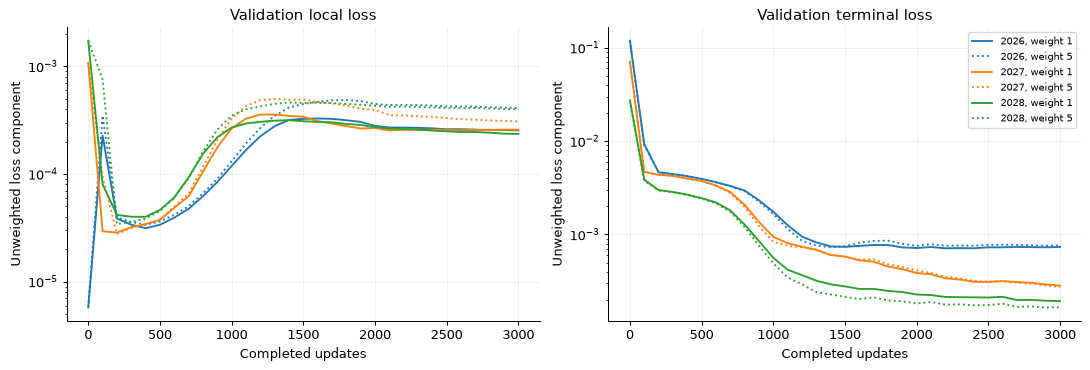

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for r in usable:
    history = reports[r["directory"]]["history"]
    color = {2026: "tab:blue", 2027: "tab:orange", 2028: "tab:green"}[r["seed"]]
    style = "-" if r["terminal_weight"] == 1 else ":"
    for ax, key, title in zip(axes, ("validation_local", "validation_terminal"),
                              ("Validation local loss", "Validation terminal loss")):
        ax.semilogy([h["step"] for h in history], [h[key] for h in history],
                    color=color, linestyle=style, label=f'{r["seed"]}, weight {r["terminal_weight"]}')
        ax.set(title=title, xlabel="Completed updates", ylabel="Unweighted loss component")
axes[1].legend(fontsize=8)
plt.show()

## 11. Exact continuation and saved-model evaluation

The continuation check pauses after update 37 of an 80-update verification run. This falls between the logging checks and precedes the learning-rate change. It restores the latest model, Adam moments and step counter, training RNG, fixed validation paths, best-checkpoint state, stopping counter and unfinished loss window. Numerical states and held-out evaluation must match the uninterrupted run exactly on the same runtime. Elapsed times are excluded.

`model.pt` contains the selected inference weights. `resume.pt` contains the latest training state, which can differ from those weights. The version 1 checkpoint from the first experiment remains readable for inference.

In [130]:
check = study["resume_check"]
table(["Continuation check", "Passed"], list(check["checks"].items()))
if not check["passed"]:
    raise RuntimeError("Continuation check failed; inspect the retained checkpoint files.")
loaded_rows = []
for r in usable:
    model = FBSNNSolver.load(study_dir / r["directory"] / "model.pt")
    point = model.initial_value()
    saved = r["selected"]
    discrepancy = max(abs(point[k]-saved[k]) for k in ("price", "delta"))
    if discrepancy > 1e-12:
        raise ArithmeticError("Loaded model disagrees with its saved evaluation.")
    loaded_rows.append([r["seed"], r["terminal_weight"], f'{point["price"]:.8f}',
                        f'{point["delta"]:.8f}', f"{discrepancy:.2g}"])
table(["Seed", "Weight", "Reloaded price", "Reloaded delta", "Max saved-point discrepancy"], loaded_rows)

Continuation check,Passed
current_weights,True
optimizer_state,True
train_rng_state,True
evaluation_rng_state,True
torch_rng_state,True
validation,True
best_state,True
best_step,True
checks_without_improvement,True
window,True


Seed,Weight,Reloaded price,Reloaded delta,Max saved-point discrepancy
2026,1,9.56716227,0.51599016,0
2026,5,9.21663969,0.48935475,0
2027,1,9.56959071,0.57105878,0
2027,5,9.67174100,0.53989506,0
2028,1,9.25924119,0.60317634,0
2028,5,9.43788557,0.64359073,0


Validation selection can reduce its own objective without improving the initial delta. Increasing terminal weight changes the optimisation balance but does not remove the finite time grid, finite network or payoff kink. Conclusions should retain both successful and missed inspection targets, runtime, seed dispersion and failed or time-limited runs. These six runs do not settle which of those mechanisms dominates the remaining error.

## 12. Terminal-loss Deep BSDE

This formulation learns a free initial value and Brownian controls. It propagates discounted values along paths rather than evaluating one global price network. For the clean pricing driver,

$$\bar Y_{m+1}=\bar Y_m+\bar Z_m\Delta W_m,\qquad
L=\frac1N\sum_n\left[\frac{\bar Y_M^{(n)}-e^{-rT}g(S_T^{(n)})}{K}\right]^2.$$

The initial discounted control is a free parameter. Each of the remaining 15 time points has its own two-layer, 16-unit tanh network using the current spot only. Controls cannot see the next increment or terminal state. The initial price and control start at zero; no analytical values initialise them. Black–Scholes enters evaluation only.

The run fixes 16 time intervals, 128 fresh paths per update, 3,000 Adam updates, seed 2026 and CPU float64. It retains the checkpoint with the smallest fixed validation terminal loss and evaluates selected and final models on identical held-out paths. The free initial scalar is **not differentiated with respect to spot to report delta**. Control-to-delta recovery and the two-solver risk comparison are separate work.

Generate the new run once from the repository root:

```bash
python -m bsde_pricing train-terminal --run-dir scratch/runs/vanilla_terminal_bsde
```

The following cells load the saved run without training. Prior value-gradient results remain above; each run's table records its own training environment.

In [131]:
from bsde_pricing.terminal_bsde import TerminalBSDESolver

terminal_dir = root / "scratch/runs/vanilla_terminal_bsde"
terminal_report = json.loads((terminal_dir / "report.json").read_text())
terminal_solver = TerminalBSDESolver.load(terminal_dir / "model.pt")
terminal_last = TerminalBSDESolver.load(terminal_dir / "last_model.pt")
for model, key in ((terminal_solver, "evaluation"), (terminal_last, "last_evaluation")):
    point = model.initial_value()
    if max(abs(point[k]-terminal_report[key]["initial"][k]) for k in ("price", "discounted_initial_control")) > 1e-12:
        raise ArithmeticError("Terminal model checkpoint disagrees with its report.")
table(["Terminal-BSDE setting", "Value"], [
    ("Status", terminal_report["status"]), ("Updates", terminal_report["completed_updates"]),
    ("Parameters", terminal_report["parameter_count"]), ("Selected update", terminal_report["selected_step"]),
    ("Configuration", terminal_report["config"]), ("Fit seconds", terminal_report["training_seconds"]),
    ("Paired evaluation seconds", terminal_report["evaluation_seconds"]),
    ("Checkpoint support", terminal_report["checkpoint_support"]),
    ("Training runtime", f'Python {terminal_report["python"]}, NumPy {terminal_report["numpy"]}, PyTorch {terminal_report["torch"]}, {terminal_report["system"]}')])
table(["Checkpoint", "Price", "Reference", "Signed price error", "Discounted initial control", "Discounted terminal RMSE"], [
    [label, f'{terminal_report[key]["initial"]["price"]:.8f}',
     f'{terminal_report[key]["initial"]["reference_price"]:.8f}',
     f'{terminal_report[key]["initial"]["price_error"]:+.8f}',
     f'{terminal_report[key]["initial"]["discounted_initial_control"]:.8f}',
     f'{terminal_report[key]["discounted_terminal_rmse"]:.6f}']
    for label, key in (("Selected", "evaluation"), ("Final", "last_evaluation"))])

Terminal-BSDE setting,Value
Status,completed
Updates,3000
Parameters,4817
Selected update,2800
Configuration,"{'batch_size': 128, 'evaluation_paths': 2048, 'iterations': 3000, 'learning_rate': 0.001, 'log_every': 100, 'max_seconds': 180, 'n_steps': 16, 'seed': 2026, 'validation_paths': 256, 'width': 16}"
Fit seconds,12.71551
Paired evaluation seconds,0.03072171
Checkpoint support,inference_only; no optimiser continuation
Training runtime,"Python 3.12.16, NumPy 2.5.4, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit"


Checkpoint,Price,Reference,Signed price error,Discounted initial control,Discounted terminal RMSE
Selected,9.40694237,9.41340338,-0.00646101,11.82480928,2.495027
Final,9.45653568,9.41340338,+0.04313230,12.04941140,2.492220


## 13. Terminal training and initial price

The terminal objective and the initial price error measure different outcomes. The price band retains the original 0.25-unit pilot inspection target. It does not trigger extra updates or choose a checkpoint. Training-window losses use pre-update batches, while validation is measured after the logged update. The dashed vertical line identifies the validation-selected update.

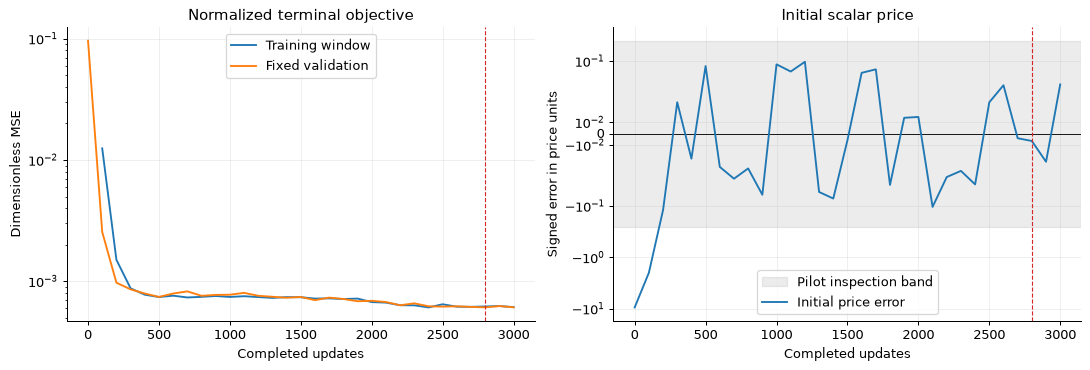

In [132]:
terminal_history = terminal_report["history"]
steps = np.array([h["step"] for h in terminal_history])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].semilogy(steps[1:], [h["training_loss_window_mean"] for h in terminal_history[1:]], label="Training window")
axes[0].semilogy(steps, [h["validation_terminal"] for h in terminal_history], label="Fixed validation")
axes[0].set(title="Normalized terminal objective", xlabel="Completed updates", ylabel="Dimensionless MSE")
axes[0].legend()
axes[1].axhspan(-0.25, 0.25, color="grey", alpha=0.15, label="Pilot inspection band")
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].plot(steps, [h["price_error"] for h in terminal_history], label="Initial price error")
axes[1].set(title="Initial scalar price", xlabel="Completed updates", ylabel="Signed error in price units")
axes[1].legend()
axes[1].set_yscale("symlog", linthresh=0.05)
for ax in axes:
    ax.axvline(terminal_report["selected_step"], linestyle="--", color="tab:red", linewidth=0.9)
plt.show()

## 14. Independent terminal residuals

The residual is propagated discounted value minus discounted payoff, in price units. RMSE includes both its mean and dispersion. Its path-level standard error describes the residual mean conditional on this trained model; it is not a confidence interval for the learned initial scalar.

The additional 512-path sample below uses seed 2027 and SeedSequence branch 3. The analytical-control comparison uses the same paths and the same left-endpoint time grid. Its residual can be nonzero because the stochastic integral is discretised. It is a diagnostic, not a claimed lower bound on the fitted loss. The learned values remain unprojected, including any negative terminal values.

Sample,Paths,Discounted terminal RMSE,Mean residual,SE of mean,Analytical-control RMSE
Saved selected,2048,2.495027,+0.014044,0.055145,2.032201
Saved final,2048,2.492220,+0.059741,0.055068,2.032201
Fresh descriptive,512,2.543842,-0.138158,0.112367,2.096407


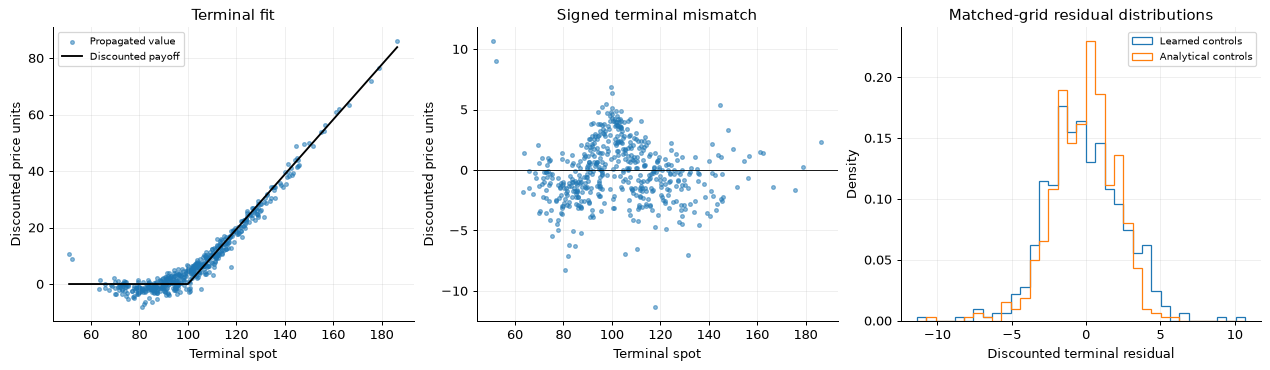

In [133]:
terminal_paths = terminal_solver.evaluate(n_paths=512, seed=2027)
table(["Sample", "Paths", "Discounted terminal RMSE", "Mean residual", "SE of mean", "Analytical-control RMSE"], [
    [label, summary["n_paths"], f'{summary["discounted_terminal_rmse"]:.6f}',
     f'{summary["terminal_residual_mean"]:+.6f}', f'{summary["terminal_residual_mean_se"]:.6f}',
     f'{summary["analytical_discounted_terminal_rmse"]:.6f}']
    for label, summary in (("Saved selected", terminal_report["evaluation"]),
                           ("Saved final", terminal_report["last_evaluation"]),
                           ("Fresh descriptive", terminal_paths.summary))])
terminal_spots = terminal_paths.spots[:, -1]
order = np.argsort(terminal_spots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
axes[0].scatter(terminal_spots, terminal_paths.discounted_values[:, -1], s=9, alpha=0.5, label="Propagated value")
axes[0].plot(terminal_spots[order], terminal_paths.discounted_payoffs[order], color="black", label="Discounted payoff")
axes[0].set(title="Terminal fit", xlabel="Terminal spot", ylabel="Discounted price units")
axes[0].legend(fontsize=8)
axes[1].scatter(terminal_spots, terminal_paths.terminal_residuals, s=9, alpha=0.5)
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set(title="Signed terminal mismatch", xlabel="Terminal spot", ylabel="Discounted price units")
bins = np.histogram_bin_edges(np.concatenate((terminal_paths.terminal_residuals, terminal_paths.analytical_terminal_residuals)), bins=35)
axes[2].hist(terminal_paths.terminal_residuals, bins=bins, histtype="step", density=True, label="Learned controls")
axes[2].hist(terminal_paths.analytical_terminal_residuals, bins=bins, histtype="step", density=True, label="Analytical controls")
axes[2].set(title="Matched-grid residual distributions", xlabel="Discounted terminal residual", ylabel="Density")
axes[2].legend(fontsize=8)
plt.show()

## 15. Propagated discounted values

The first three fresh paths are displayed without selection by fit quality. Each solid line is the learned initial scalar plus its accumulated stochastic integral. The dashed line is the analytical discounted conditional value along the same spot path. These propagated values depend on the preceding path history; they are not evaluations of a globally learned price surface. An accurate initial scalar alone does not establish accurate controls or terminal matching.

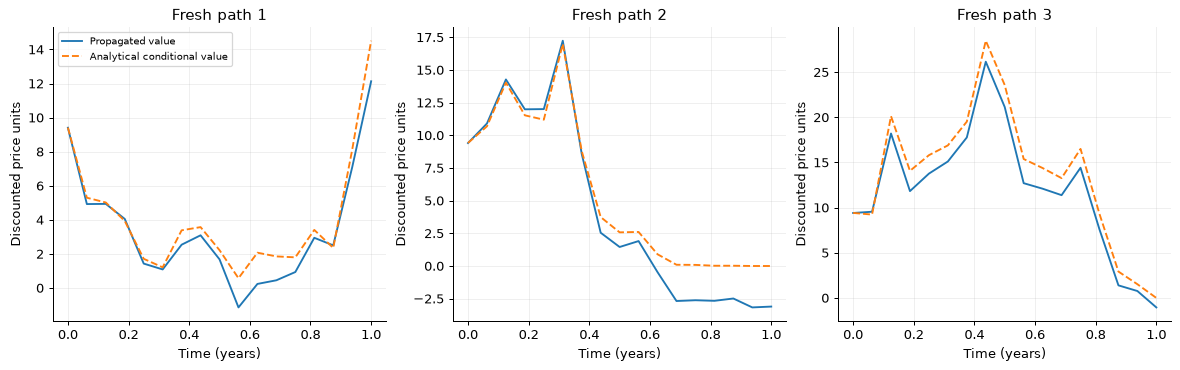

In [134]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for index, ax in enumerate(axes):
    reference = np.array([terminal_solver.reference.evaluate(float(spot), float(t)).call_price
                          for t, spot in zip(terminal_paths.times, terminal_paths.spots[index])])
    discount = np.exp(-terminal_solver.case.model.rate*terminal_paths.times)
    ax.plot(terminal_paths.times, terminal_paths.discounted_values[index], label="Propagated value")
    ax.plot(terminal_paths.times, discount*reference, "--", label="Analytical conditional value")
    ax.set(title=f"Fresh path {index+1}", xlabel="Time (years)", ylabel="Discounted price units")
axes[0].legend(fontsize=8)
plt.show()

This bounded first run assesses initial price and terminal residuals. It supplies a distinct terminal-loss formulation for the later risk comparison. The initial scalar has no spot derivative, the saved files support inference only, and no seed robustness or higher-dimensional accuracy conclusion follows from this one run.

## 16. A common price and risk comparison

The comparison loads the already selected seed-2026, weight-one value-gradient model from the reproducibility study and the selected terminal-loss model. Their saved update counts and checkpoint rules are reported explicitly; the original first experiment remains above. Neither model is retrained or selected using these comparison results.

For a physical diffusion matrix $\Sigma(S)$ and undiscounted Brownian control $Z$, delta solves

$$\Sigma(S)^\top\Delta=Z.$$

The terminal solver stores discounted controls. In one asset the conversion is therefore

$$Z_t=e^{rt}\bar Z_t,\qquad\Delta_t=\frac{e^{rt}\bar Z_t}{\sigma S_t}.$$

The value-gradient model supplies delta by differentiating its price map; its control is reconstructed through the same diffusion map. Both are compared with the same Black–Scholes price and delta. The control reconstruction residual checks numerical algebra, not whether a learned control is financially accurate.

Generate the comparison from the repository root without fitting:

```bash
python -m bsde_pricing compare-risk --run-dir scratch/runs/vanilla_risk_comparison
```

The default value run is `scratch/runs/reproducibility/seed_2026_weight_1`; the terminal run is `scratch/runs/vanilla_terminal_bsde`. Results contain a JSON report and matched-path arrays. These cells load that evidence without recomputing timings or training.

Model,Price,Price error,Delta,Delta error,Control,Price / delta targets met
Terminal loss,9.40694237,-0.00646101,0.59124046,-0.00746586,11.82480928,"{'delta': True, 'price': True}"
Value-gradient,9.56716227,+0.15375889,0.51599016,-0.08271617,10.31980314,"{'delta': False, 'price': True}"


Model,Parameters,Selected / completed update,Recorded fit seconds,Training runtime
Terminal loss,4817,2800 / 3000,12.71551,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"
Value-gradient,337,2400 / 3000,6.71159,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"


Comparison setting,Value
Paths,2048
Steps,16
Seed / branch,"(2031, 4)"
CPU threads,1
Training performed,False
Runtime,"Python 3.12.16, NumPy 2.5.4, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit"


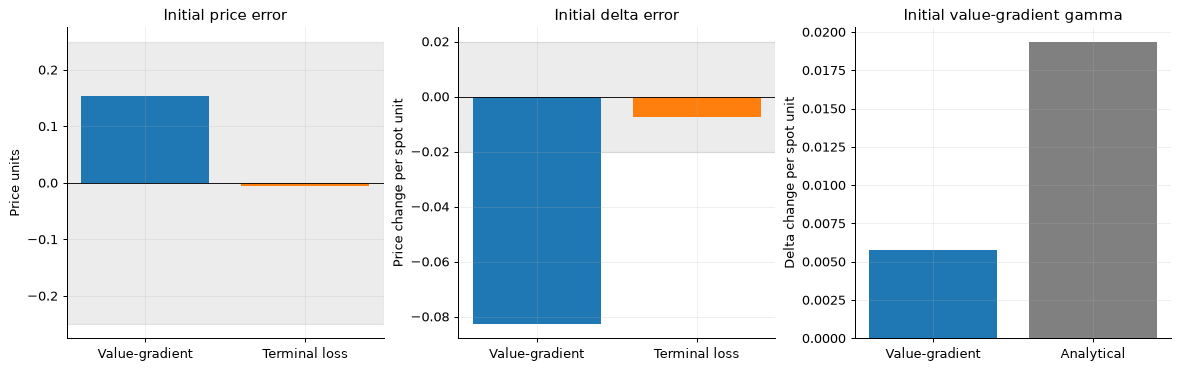

In [135]:
from bsde_pricing.risk_comparison import RiskComparisonResult

risk_dir = root / "scratch/runs/vanilla_risk_comparison"
risk = RiskComparisonResult.load(risk_dir)
risk_report = risk.report
names = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
model_rows = risk_report["models"]
table(["Model", "Price", "Price error", "Delta", "Delta error", "Control", "Price / delta targets met"], [
    [names[k], f'{v["initial"]["price"]:.8f}', f'{v["initial"]["price_error"]:+.8f}',
     f'{v["initial"]["delta"]:.8f}', f'{v["initial"]["delta_error"]:+.8f}',
     f'{v["initial"]["brownian_control"]:.8f}', risk_report["targets_met"][k]]
    for k,v in model_rows.items()])
table(["Model", "Parameters", "Selected / completed update", "Recorded fit seconds", "Training runtime"], [
    [names[k], model_rows[k]["parameter_count"], f'{s["selected_step"]} / {s["completed_updates"]}',
     f'{s["training_seconds"]:.5f}', s["training_runtime"]] for k,s in risk_report["source_runs"].items()])
table(["Comparison setting", "Value"], [("Paths", risk_report["n_paths"]), ("Steps", risk_report["n_steps"]),
    ("Seed / branch", (risk_report["seed"], risk_report["seed_sequence_branch"])),
    ("CPU threads", risk_report["cpu_threads"]), ("Training performed", risk_report["trained_during_comparison"]),
    ("Runtime", f'Python {risk_report["python"]}, NumPy {risk_report["numpy"]}, PyTorch {risk_report["torch"]}, {risk_report["system"]}')])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
keys = ["value_gradient", "terminal_loss"]
for ax, metric, band, title in zip(axes[:2], ("price_error", "delta_error"), (0.25, 0.02),
                                   ("Initial price error", "Initial delta error")):
    ax.axhspan(-band, band, color="grey", alpha=0.15, label="Pilot inspection band")
    ax.bar([names[k] for k in keys], [model_rows[k]["initial"][metric] for k in keys], color=["tab:blue", "tab:orange"])
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(title)
axes[0].set_ylabel("Price units")
axes[1].set_ylabel("Price change per spot unit")
gamma = risk_report["value_gradient_gamma"]
axes[2].bar(["Value-gradient", "Analytical"], [gamma["gamma"], gamma["reference_gamma"]], color=["tab:blue", "grey"])
axes[2].set(title="Initial value-gradient gamma", ylabel="Delta change per spot unit")
plt.show()

## 17. Deltas on matched fresh states

The comparison uses 2,048 new paths from seed 2031, SeedSequence branch 4, and excludes expiry deltas. Both methods see identical spots at the same time points. The sample is descriptive evidence for these frozen models; it does not estimate variation across training seeds. Standard errors for mean signed delta errors use one time-averaged error per independent path. Bound counts use the call bounds $0\leq\Delta\leq e^{-q(T-t)}$ with a 1e-10 roundoff allowance; the denominator includes every path/time pair and does not represent independent observations.

Sorted state slices connect predictions on sampled states at each selected time. These are local evaluations supported by this fixed-start experiment, not evidence of generalisation to different model parameters or starting spots.

Model,Delta RMSE,Mean signed error,SE of mean
Terminal loss,0.083971,+0.001446,0.001047
Value-gradient,0.112785,-0.011999,0.001637


Model,Minimum delta,Maximum delta,Bound violations / state evaluations,Max absolute delta error
Terminal loss,-1.281942,1.228014,3136 / 32768,1.281942
Value-gradient,-0.104866,1.182824,1541 / 32768,0.880815


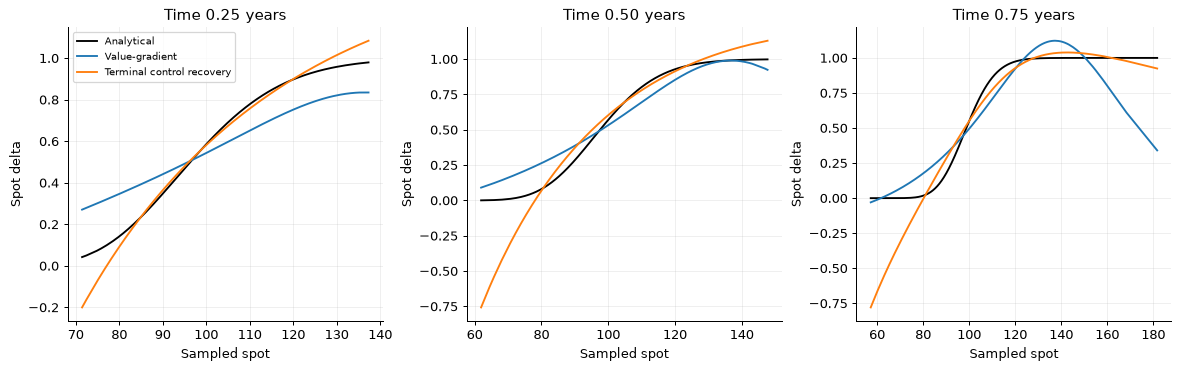

In [136]:
table(["Model", "Delta RMSE", "Mean signed error", "SE of mean"], [
    [names[k], f'{v["path_delta_rmse"]:.6f}', f'{v["path_delta_mean_error"]:+.6f}',
     f'{v["path_delta_mean_error_se"]:.6f}'] for k,v in model_rows.items()])
table(["Model", "Minimum delta", "Maximum delta", "Bound violations / state evaluations", "Max absolute delta error"], [
    [names[k], f'{v["path_delta_min"]:.6f}', f'{v["path_delta_max"]:.6f}',
     f'{v["delta_bound_violation_count"]} / {v["path_risk_evaluation_count"]}', f'{v["max_absolute_path_delta_error"]:.6f}']
    for k,v in model_rows.items()])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, fraction in zip(axes, (0.25, 0.5, 0.75)):
    m = int(round(fraction*risk_report["n_steps"]))
    spots = risk.spots[:, m]
    order = np.argsort(spots)
    ax.plot(spots[order], risk.reference_deltas[order,m], color="black", label="Analytical")
    ax.plot(spots[order], risk.value_deltas[order,m], label="Value-gradient")
    ax.plot(spots[order], risk.terminal_deltas[order,m], label="Terminal control recovery")
    ax.set(title=f"Time {risk.times[m]:.2f} years", xlabel="Sampled spot", ylabel="Spot delta")
axes[0].legend(fontsize=8)
plt.show()

## 18. Diffusion conditioning and reconstruction

In this one-asset case, $\Sigma(S)=\sigma S$ is a nonzero scalar and its 2-norm condition number is always one. That alone does not describe absolute error amplification:

$$|\delta\Delta|\leq\|\Sigma^{-\top}\|_2\,|\delta Z|,
\qquad\|\Sigma^{-\top}\|_2=\frac1{\sigma S}.$$

The table reports both quantities. In several assets, the smallest singular value and the condition number also expose near-singular dependence. The common inverse rejects a singular diffusion without clipping or regularisation. A small reconstruction residual means the computed delta reproduces the supplied control; the control can still be wrong relative to the analytical reference.

Model,Max absolute reconstruction residual,Max relative residual,Condition range,Min diffusion singular value,Max inverse norm
Terminal loss,7.11e-15,3.68e-16,"(1.0, 1.0)",10.408279,0.096077
Value-gradient,7.11e-15,3.69e-16,"(1.0, 1.0)",10.408279,0.096077


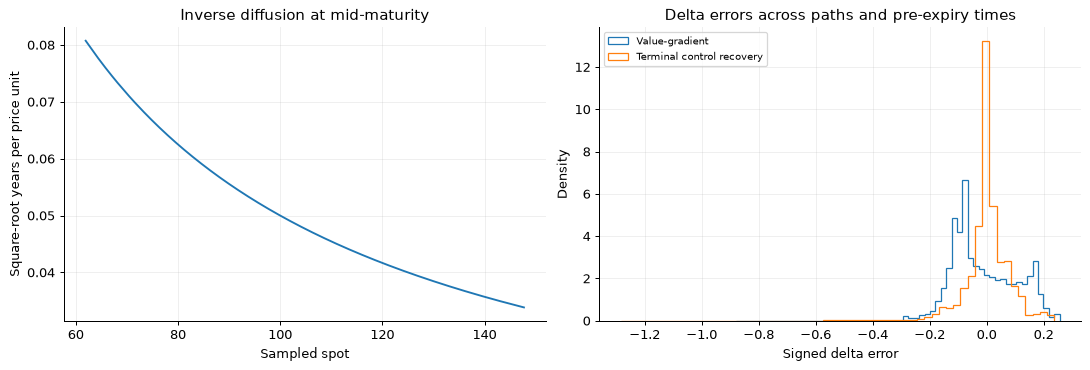

In [137]:
table(["Model", "Max absolute reconstruction residual", "Max relative residual", "Condition range", "Min diffusion singular value", "Max inverse norm"], [
    [names[k], f'{d["max_absolute_reconstruction_residual"]:.3g}', f'{d["max_relative_reconstruction_residual"]:.3g}',
     (d["condition_number_min"], d["condition_number_max"]), f'{d["smallest_diffusion_singular_value"]:.6f}',
     f'{d["largest_inverse_diffusion_norm"]:.6f}']
    for k,v in model_rows.items() for d in [v["path_reconstruction"]]])
m = risk_report["n_steps"]//2
order = np.argsort(risk.spots[:,m])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(risk.spots[order,m], risk.inverse_norms[order,m])
axes[0].set(title="Inverse diffusion at mid-maturity", xlabel="Sampled spot", ylabel="Square-root years per price unit")
for values, name in ((risk.value_deltas, "Value-gradient"), (risk.terminal_deltas, "Terminal control recovery")):
    axes[1].hist((values-risk.reference_deltas).ravel(), bins=60, density=True, histtype="step", label=name)
axes[1].set(title="Delta errors across paths and pre-expiry times", xlabel="Signed delta error", ylabel="Density")
axes[1].legend(fontsize=8)
plt.show()

## 19. Gamma consistency and measured costs

The value-gradient model has a differentiable price function, so its physical spot Hessian supplies gamma. The bump check differentiates its delta numerically using fixed relative spot bumps. Agreement verifies an internal derivative of this network. It does not establish agreement with analytical gamma or accuracy for other starting states.

The terminal solver supplies a fixed-start scalar and controls. A comparable global price Hessian is not available from this representation; terminal gamma is left undefined here.

Initial inference timings include price, delta, control mapping/inversion and diffusion diagnostics, with two warmups and five measured repeats. They exclude model loading, references and training. The separate batch timing covers risk evaluation and recovery on all matched states, excluding path generation and references. These short measurements describe the retained workloads; they are not a cost/accuracy speedup claim. Recorded fitting times and parameter counts differ and remain visible.

In [138]:
table(["Gamma quantity", "Value"], [("Value-gradient gamma", gamma["gamma"]),
    ("Analytical gamma", gamma["reference_gamma"]), ("Signed gamma error", gamma["signed_error"]),
    ("Terminal gamma", risk_report["terminal_gamma_reason"])])
table(["Relative bump", "Spot bump", "Central delta-bump gamma", "Difference from autograd"], [
    [b["fraction"], b["size"], f'{b["central_delta_bump_gamma"]:.10f}', f'{b["error_against_autograd"]:+.3g}']
    for b in gamma["bump_checks"]])
table(["Model", "Initial inference median (ms)", "All initial repeats (ms)", "Matched-path risk seconds"], [
    [names[k], f'{v["timing"]["initial_median_seconds"]*1000:.4f}',
     [round(t*1000,4) for t in v["timing"]["initial_seconds"]], f'{v["timing"]["path_risk_seconds"]:.5f}']
    for k,v in model_rows.items()])

Gamma quantity,Value
Value-gradient gamma,0.005783716
Analytical gamma,0.01933341
Signed gamma error,-0.01354969
Terminal gamma,fixed-start control representation; no global price Hessian


Relative bump,Spot bump,Central delta-bump gamma,Difference from autograd
0.01,1,0.0057836368,-7.9e-08
0.005,0.5,0.0057836961,-1.97e-08
0.001,0.1,0.0057837150,-7.86e-10


Model,Initial inference median (ms),All initial repeats (ms),Matched-path risk seconds
Terminal loss,0.0769,"[0.0819, 0.0786, 0.0769, 0.0728, 0.0719]",0.06408
Value-gradient,0.2055,"[0.218, 0.2125, 0.2055, 0.1996, 0.1995]",0.07334


The initial price/delta comparison, matched-state risk errors and value-gradient gamma assess different aspects of the frozen models. Neither an exact algebraic reconstruction nor an accurate initial price certifies the full risk surface. The result remains one declared seed and two different architectures; broader seed, grid and dimension conclusions require the later experiments.

## 20. Five-asset geometric call

The weighted geometric basket is $G=\prod_i S_i^{w_i}$. Unequal spots, weights, volatilities and dividends distinguish the coordinate risks. Correlation uses $\rho_{ij}=b_i b_j$ off the diagonal with unit diagonal. The mixed-sign loadings give both positive and negative correlations. Positive idiosyncratic variances $1-b_i^2$ make the matrix positive definite.

The geometric basket has an exact lognormal reduction. Its effective variance is $(w\odot\sigma)^\top\rho(w\odot\sigma)$ and its coordinate delta is $\Delta_G w_i G/S_i$. The value-gradient network returns a scalar and differentiates it in each spot. The terminal model learns one discounted control per Brownian coordinate. After undiscounting, its delta vector solves $\Sigma(S)^\top\Delta=Z$.

Run both fits with the declared seed and full budget, then evaluate their saved checkpoints on a fresh shared grid.

```bash
python -m bsde_pricing train --case geometric-five
python -m bsde_pricing train-terminal --case geometric-five
python -m bsde_pricing compare-risk \
  --value-run scratch/runs/geometric_five_fbsnn \
  --terminal-run scratch/runs/geometric_five_terminal_bsde \
  --run-dir scratch/runs/geometric_five_risk
```

The following cells read the saved comparison and record its runtime and source fits.

In [139]:
basket_risk = RiskComparisonResult.load(root / "scratch/runs/geometric_five_risk")
basket_report = basket_risk.report
basket_problem = basket_report["problem"]
basket_models = basket_report["models"]
basket_keys = ("value_gradient", "terminal_loss")
basket_labels = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
basket_assets = np.arange(1, 6)
basket_model = basket_problem["model"]
table(["Asset", "Spot", "Weight", "Volatility", "Dividend yield"], [
    [i+1, basket_problem["initial_spots"][i], basket_problem["contract"]["weights"][i],
     basket_model["volatilities"][i], basket_model["dividend_yields"][i]] for i in range(5)])
table(["Model", "Parameters", "Selected / completed update", "Fit seconds", "Runtime"], [
    [basket_labels[k], basket_models[k]["parameter_count"],
     f'{basket_report["source_runs"][k]["selected_step"]} / {basket_report["source_runs"][k]["completed_updates"]}',
     f'{basket_report["source_runs"][k]["training_seconds"]:.4f}', basket_report["source_runs"][k]["training_runtime"]]
    for k in basket_keys])
table(["Comparison setting", "Value"], [
    ("Paths / intervals", (basket_report["n_paths"], basket_report["n_steps"])),
    ("Seed / branch", (basket_report["seed"], basket_report["seed_sequence_branch"])),
    ("Runtime", f'Python {basket_report["python"]}, NumPy {basket_report["numpy"]}, PyTorch {basket_report["torch"]}, {basket_report["system"]}'),
])

Asset,Spot,Weight,Volatility,Dividend yield
1,90,0.1,0.16,0.005
2,100,0.15,0.19,0.01
3,110,0.2,0.23,0.015
4,95,0.25,0.26,0.02
5,105,0.3,0.31,0.025


Model,Parameters,Selected / completed update,Fit seconds,Runtime
Value-gradient,401,3000 / 3000,9.0582,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"
Terminal loss,6801,2700 / 3000,15.0891,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"


Comparison setting,Value
Paths / intervals,"(2048, 16)"
Seed / branch,"(2031, 4)"
Runtime,"Python 3.12.16, NumPy 2.5.4, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit"


## 21. Price and five coordinate deltas

Both models use seed 2026, 3,000 updates and a 16-interval grid. Each checkpoint follows its solver's validation objective. The independent comparison uses 2,048 paths with seed 2031 and SeedSequence branch 4. The price inspection band is 0.25 and the delta band is 0.02 per coordinate. The tables keep signed initial errors and per-coordinate path RMSE visible.

Model,Initial price,Reference price,Signed price error,Price / all delta targets
Value-gradient,5.76936224,5.49471932,+0.27464292,"{'delta': False, 'price': False}"
Terminal loss,5.52561574,5.49471932,+0.03089642,"{'delta': True, 'price': True}"


Asset,Reference delta,Value-gradient delta,Value-gradient error,Terminal delta,Terminal error
1,0.05718615,0.05822444,+0.00103829,0.06580757,+0.00862142
2,0.07720131,0.06778033,-0.00942098,0.08202871,+0.00482740
3,0.09357734,0.07183337,-0.02174397,0.09580589,+0.00222855
4,0.13544089,0.12984272,-0.00559817,0.13736161,+0.00192072
5,0.14705011,0.14888201,+0.00183190,0.14531924,-0.00173087


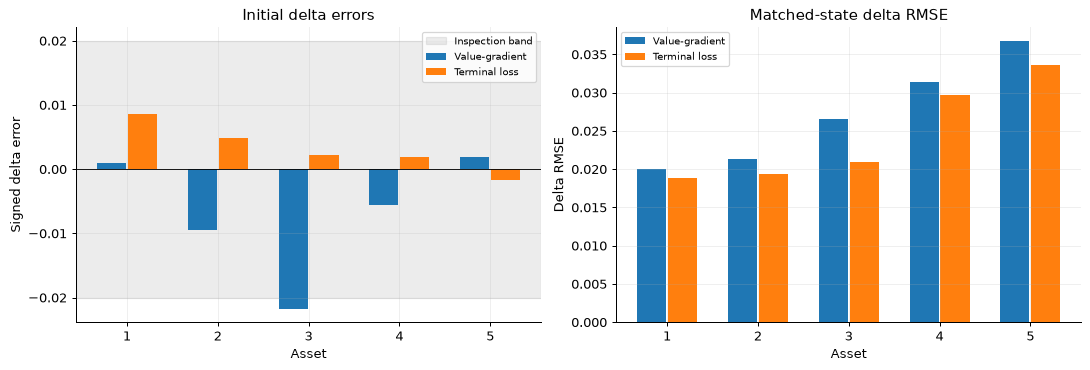

In [140]:
basket_initial = {k: basket_models[k]["initial"] for k in basket_keys}
basket_reference = basket_initial["value_gradient"]
table(["Model", "Initial price", "Reference price", "Signed price error", "Price / all delta targets"], [
    [basket_labels[k], f'{basket_initial[k]["price"]:.8f}', f'{basket_reference["reference_price"]:.8f}',
     f'{basket_initial[k]["price_error"]:+.8f}', basket_report["targets_met"][k]] for k in basket_keys])
table(["Asset", "Reference delta", "Value-gradient delta", "Value-gradient error", "Terminal delta", "Terminal error"], [
    [i+1, f'{basket_reference["reference_delta"][i]:.8f}',
     f'{basket_initial["value_gradient"]["delta"][i]:.8f}', f'{basket_initial["value_gradient"]["delta_error"][i]:+.8f}',
     f'{basket_initial["terminal_loss"]["delta"][i]:.8f}', f'{basket_initial["terminal_loss"]["delta_error"][i]:+.8f}']
    for i in range(5)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].axhspan(-0.02, 0.02, color="grey", alpha=0.15, label="Inspection band")
axes[0].axhline(0, color="black", linewidth=0.7)
for k, shift in zip(basket_keys, (-0.17, 0.17)):
    axes[0].bar(basket_assets+shift, basket_initial[k]["delta_error"], width=0.32, label=basket_labels[k])
    axes[1].bar(basket_assets+shift, basket_models[k]["path_delta_rmse_by_coordinate"], width=0.32, label=basket_labels[k])
axes[0].set(title="Initial delta errors", ylabel="Signed delta error")
axes[1].set(title="Matched-state delta RMSE", ylabel="Delta RMSE")
for ax in axes:
    ax.set(xlabel="Asset", xticks=basket_assets)
    ax.legend(fontsize=8)
plt.show()

## 22. Diffusion recovery and risk tails

The recovered controls reconstruct to floating-point accuracy. The bound check separately counts predicted deltas outside $[0,e^{-q_{\mathrm{eff}}(T-t)}w_iG/S_i]$ with a $10^{-10}$ roundoff allowance. Each coordinate has 32,768 path/time evaluations. Counts and maxima describe this shared sample and keep the tails visible alongside RMSE.

Model,Condition range,Max inverse norm,Max reconstruction residual,Worst delta error
Value-gradient,"(1.85138, 6.63706)",0.141453,4.55e-15,0.219419
Terminal loss,"(1.85138, 6.63706)",0.141453,5.69e-15,0.452072


Asset,Value-gradient RMSE,Terminal RMSE,Value-gradient bound violations,Terminal bound violations
1,0.019967,0.018884,2269,3187
2,0.021320,0.019431,1393,3045
3,0.026625,0.020927,1244,2828
4,0.031419,0.029740,1411,2568
5,0.036697,0.033634,1167,2479


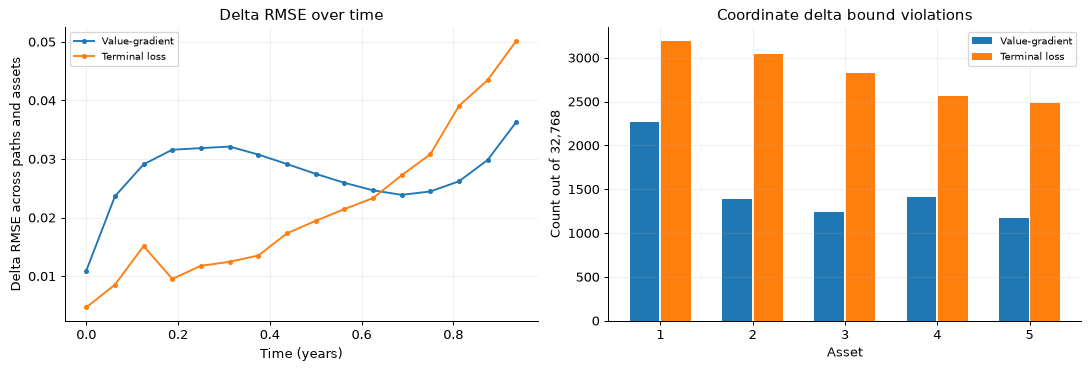

In [141]:
table(["Model", "Condition range", "Max inverse norm", "Max reconstruction residual", "Worst delta error"], [
    [basket_labels[k], (round(d["condition_number_min"], 5), round(d["condition_number_max"], 5)),
     f'{d["largest_inverse_diffusion_norm"]:.6f}', f'{d["max_absolute_reconstruction_residual"]:.3g}',
     f'{basket_models[k]["max_absolute_path_delta_error"]:.6f}']
    for k in basket_keys for d in [basket_models[k]["path_reconstruction"]]])
table(["Asset", "Value-gradient RMSE", "Terminal RMSE", "Value-gradient bound violations", "Terminal bound violations"], [
    [i+1, f'{basket_models["value_gradient"]["path_delta_rmse_by_coordinate"][i]:.6f}',
     f'{basket_models["terminal_loss"]["path_delta_rmse_by_coordinate"][i]:.6f}',
     basket_models["value_gradient"]["delta_bound_violations_by_coordinate"][i],
     basket_models["terminal_loss"]["delta_bound_violations_by_coordinate"][i]] for i in range(5)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for (k, estimates), shift in zip((("value_gradient", basket_risk.value_deltas),
                                  ("terminal_loss", basket_risk.terminal_deltas)), (-0.17, 0.17)):
    by_time = np.sqrt(np.mean((estimates-basket_risk.reference_deltas)**2, axis=(0, 2)))
    axes[0].plot(basket_risk.times[:-1], by_time, marker="o", markersize=3, label=basket_labels[k])
    axes[1].bar(basket_assets+shift, basket_models[k]["delta_bound_violations_by_coordinate"],
                width=0.32, label=basket_labels[k])
axes[0].set(title="Delta RMSE over time", xlabel="Time (years)", ylabel="Delta RMSE across paths and assets")
axes[1].set(title="Coordinate delta bound violations", xlabel="Asset", ylabel="Count out of 32,768", xticks=basket_assets)
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

## 23. Ten-asset arithmetic reference

The arithmetic basket is $A_T=\sum_i w_i S_T^i$. This development case has ten spots of 100, equal weights of 0.10, 20% volatility, no dividends, correlation 0.30, maturity one year, strike 100 and a 3% rate. The payoff remains a function of the full correlated terminal vector. A geometric basket supplies a control variate with a known expectation.

Run the bounded experiment once from the repository root. The command saves the design, reference, both selected checkpoints, source histories and resource measurements. These cells only read the saved evidence.

```bash
python -m bsde_pricing arithmetic-pilot
```

Each Sobol level uses 16 independent scrambles. The primary level has $2^{16}$ points per scramble, with a $2^{12}$ refinement comparison using the same seeds. A separate IID check uses 131,072 antithetic pairs and a different seed. Each method fits its geometric-control coefficients on an independent 4,096-pair pilot. Confidence intervals use scramble means or antithetic pair means as sampling units.

The roadmap targets are 0.01 in price and 0.01 in each weight-scaled delta $\Delta_i/w_i$. The allocated reference half-width is 20% of each target. Intervals are approximate pointwise 95% intervals. The ten coordinate intervals are correlated and do not provide simultaneous 95% coverage.


Reference,Evaluation terminal states,Controlled price,95% half-width,Calculation seconds
Sobol 2^12,65536,6.407143,0.001848605,0.06205483
Sobol 2^16,1048576,6.406184,0.0003619206,0.6308393
Antithetic IID check,262144,6.407722,0.002266164,0.1496516


Reference budget,Observed,Allocated,Met
Price half-width,0.0003619206,0.002,True
Largest weight-scaled delta half-width,0.0003368865,0.002,True


Sobol minus IID check,Signed difference,Difference / combined SE
Price,-0.001537609,-1.315737
Delta 1,-0.0001267292,-2.753649
Delta 2,-0.0001296298,-2.843791
Delta 3,-0.0001416046,-3.082745
Delta 4,-0.0001075817,-2.356077
Delta 5,-0.0001486529,-3.248802
Delta 6,-0.0001302746,-2.883108
Delta 7,-8.380129e-05,-1.840067
Delta 8,-9.225803e-05,-2.01209
Delta 9,-0.0001107524,-2.436642


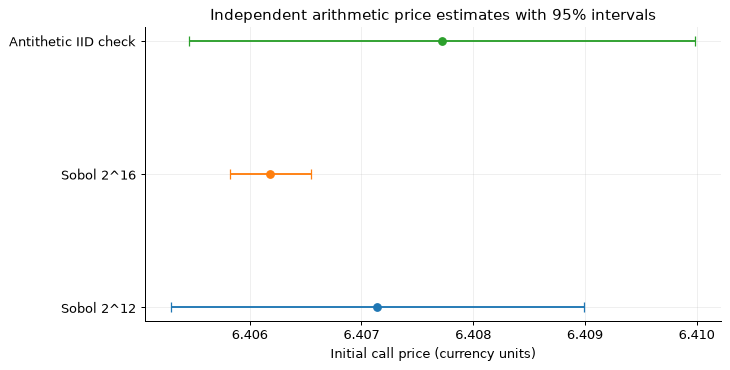

In [142]:
arithmetic_dir = root / "scratch/runs/arithmetic_ten_pilot"
arithmetic_report = json.loads((arithmetic_dir / "report.json").read_text())
arithmetic_ref = arithmetic_report["reference"]
arithmetic_config = arithmetic_report["config"]
arithmetic_weights = np.asarray(arithmetic_report["problem"]["contract"]["weights"])
arithmetic_models = arithmetic_report["models"]
arithmetic_keys = ("value_gradient", "terminal_loss")
arithmetic_names = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
arithmetic_rows = [(f'Sobol 2^{r["power"]}', r) for r in arithmetic_ref["sobol_levels"]]
arithmetic_rows.append(("Antithetic IID check", arithmetic_ref["antithetic_check"]))
table(["Reference", "Evaluation terminal states", "Controlled price", "95% half-width", "Calculation seconds"], [
    [label, r["evaluation_terminal_states"], r["controlled"]["price"]["estimate"],
     (r["controlled"]["price"]["confidence_high"]-r["controlled"]["price"]["confidence_low"])/2, r["seconds"]]
    for label, r in arithmetic_rows])
table(["Reference budget", "Observed", "Allocated", "Met"], [
    ["Price half-width", arithmetic_ref["reference_price_half_width"],
     arithmetic_config["price_target"]*arithmetic_config["reference_fraction"], arithmetic_ref["error_budget_met"]["price"]],
    ["Largest weight-scaled delta half-width", max(arithmetic_ref["reference_scaled_delta_half_widths"]),
     arithmetic_config["scaled_delta_target"]*arithmetic_config["reference_fraction"], arithmetic_ref["error_budget_met"]["all_scaled_deltas"]]])
table(["Sobol minus IID check", "Signed difference", "Difference / combined SE"], [
    ["Price" if j == 0 else f"Delta {j}", r["signed_difference"], r["difference_in_standard_errors"]]
    for j, r in enumerate(arithmetic_ref["independent_method_agreement"])])
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for j, (label, r) in enumerate(arithmetic_rows):
    s = r["controlled"]["price"]
    ax.errorbar(s["estimate"], j, xerr=(s["confidence_high"]-s["confidence_low"])/2,
                fmt="o", capsize=4, label=label)
ax.set(yticks=range(len(arithmetic_rows)), yticklabels=[r[0] for r in arithmetic_rows],
       xlabel="Initial call price (currency units)", title="Independent arithmetic price estimates with 95% intervals")
plt.show()


## 24. Saved initial prices and ten deltas

Both fits retain 3,000 updates, 128 training paths per update, 16 intervals, hidden width 16 and seed 2026. CPU float64 is used throughout. Checkpoint selection uses the solver's own fixed validation objective. Numerical reference prices and deltas are computed in a separate process and enter the comparison after fitting.

For a fixed learned value $v$ and numerical reference interval $[a,b]$, the signed price-error interval is $[v-b,v-a]$. Coordinate errors and their intervals are divided by $w_i$. A target is met only if the entire error interval lies inside its band. An interval crossing the target boundary is labelled unresolved at reference precision. Missing analytical path references are recorded as null in the solver reports. Terminal-payoff mismatch remains measurable for both formulations.

The earlier 0.25 price and 0.02 raw-delta inspection bands remain historical pilot diagnostics. This section assesses the original roadmap targets and keeps their different units explicit.


Model,Initial price,Signed price error,95% error interval,0.01 target
Value-gradient,6.545178,0.1389942,"[0.13863230662934534, 0.1393561479189902]",outside_target
Terminal loss,6.417705,0.01152083,"[0.011158904359290567, 0.011882745648935433]",outside_target


Asset,Reference delta,Value-gradient delta,Scaled error,Terminal delta,Scaled error,Terminal classification
1,0.06205644,0.06332829,0.01271847,0.05536382,-0.06692621,outside_target
2,0.06205976,0.07515089,0.1309113,0.0630756,0.01015848,unresolved_at_reference_precision
3,0.06205965,0.05442991,-0.07629742,0.06578262,0.03722972,outside_target
4,0.06205727,0.06730738,0.05250114,0.06402795,0.01970688,outside_target
5,0.0620544,0.06487484,0.02820446,0.05918592,-0.02868474,outside_target
6,0.06205936,0.05586342,-0.0619594,0.06438542,0.02326057,outside_target
7,0.06205971,0.05385863,-0.08201079,0.05661401,-0.05445697,outside_target
8,0.06205793,0.05453418,-0.07523751,0.06686803,0.04810103,outside_target
9,0.06205698,0.06431697,0.02259994,0.05292142,-0.09135559,outside_target
10,0.06205671,0.05620806,-0.05848653,0.06334506,0.01288345,outside_target


Model,Initial bound violations,Diffusion condition,Max reconstruction residual,Path delta RMSE
Value-gradient,0,2.299068,1.153778e-15,Unavailable without conditional references
Terminal loss,0,2.299068,5.43896e-16,Unavailable without conditional references


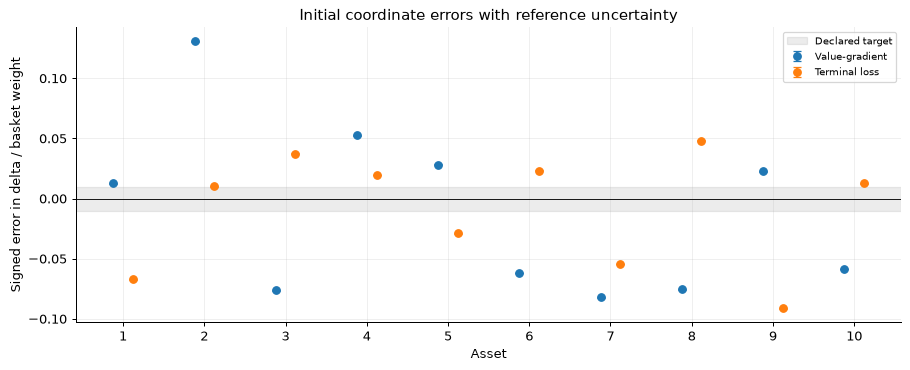

In [143]:
table(["Model", "Initial price", "Signed price error", "95% error interval", "0.01 target"], [
    [arithmetic_names[k], m["initial"]["price"], m["price_check"]["signed_error"],
     m["price_check"]["signed_error_interval"], m["price_check"]["classification"]]
    for k in arithmetic_keys for m in [arithmetic_models[k]]])
table(["Asset", "Reference delta", "Value-gradient delta", "Scaled error", "Terminal delta", "Scaled error", "Terminal classification"], [
    [i+1, arithmetic_ref["primary"]["deltas"][i]["estimate"],
     arithmetic_models["value_gradient"]["initial"]["delta"][i],
     arithmetic_models["value_gradient"]["scaled_delta_checks"][i]["signed_error"],
     arithmetic_models["terminal_loss"]["initial"]["delta"][i],
     arithmetic_models["terminal_loss"]["scaled_delta_checks"][i]["signed_error"],
     arithmetic_models["terminal_loss"]["scaled_delta_checks"][i]["classification"]] for i in range(10)])
table(["Model", "Initial bound violations", "Diffusion condition", "Max reconstruction residual", "Path delta RMSE"], [
    [arithmetic_names[k], arithmetic_models[k]["initial_delta_bound_violations"],
     arithmetic_models[k]["initial"]["reconstruction"]["condition_number_max"],
     arithmetic_models[k]["initial"]["reconstruction"]["max_absolute_reconstruction_residual"],
     "Unavailable without conditional references"] for k in arithmetic_keys])
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for k, shift in zip(arithmetic_keys, (-0.12, 0.12)):
    checks = arithmetic_models[k]["scaled_delta_checks"]
    ax.errorbar(np.arange(1, 11)+shift, [r["signed_error"] for r in checks],
                yerr=arithmetic_ref["reference_scaled_delta_half_widths"], fmt="o", capsize=3, label=arithmetic_names[k])
ax.axhspan(-arithmetic_config["scaled_delta_target"], arithmetic_config["scaled_delta_target"],
           color="grey", alpha=0.15, label="Declared target")
ax.axhline(0, color="black", linewidth=0.7)
ax.set(xticks=np.arange(1, 11), xlabel="Asset", ylabel="Signed error in delta / basket weight",
       title="Initial coordinate errors with reference uncertainty")
ax.legend(fontsize=8)
plt.show()


## 25. Runtime, resident memory and the next budget

The reference and two fits run sequentially in separate Python processes. Fit time measures the solver's training loop. Paired evaluation time covers the final and validation-selected checkpoints. Process wall time includes startup, imports, computation and saving. Each worker's peak resident memory includes its libraries and allocator footprint. Linux uses the executed image's `VmHWM`, while macOS uses `getrusage` in bytes. Controller memory and other running applications require additional headroom.

The three-seed projection repeats this exact ten-asset configuration three times. It excludes higher dimensions, tuning and the later locked suite. A single development seed establishes a feasible pilot cost and exposes accuracy misses. The training curves display each solver's validation objective separately.


Model,Parameters,Selected / completed update,Fit seconds,Paired evaluation seconds,Runtime
Value-gradient,481,3000 / 3000,8.919158,0.07376963,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"
Terminal loss,9281,2900 / 3000,17.13854,0.06894442,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"


Task,Process wall seconds,Peak resident MiB,Memory source,System
reference,1.767185,336.5625,getrusage ru_maxrss bytes,macOS-27.0.1-arm64-arm-64bit
terminal_loss,19.21457,308.0781,getrusage ru_maxrss bytes,macOS-27.0.1-arm64-arm-64bit
value_gradient,10.75648,339.0469,getrusage ru_maxrss bytes,macOS-27.0.1-arm64-arm-64bit


Budget quantity,Value
basis,three repeats of this exact case and configuration; excludes later dimensions and tuning
largest_worker_peak_resident_mib,339.0469
three_seed_fit_and_evaluation_seconds,78.60123
three_seed_fit_seconds,78.17309
worker_memory_scope,largest individual worker RSS; controller and other applications are additional
Controller peak resident MiB,210.125
Installed physical GiB,8
Total pilot wall seconds,31.8233


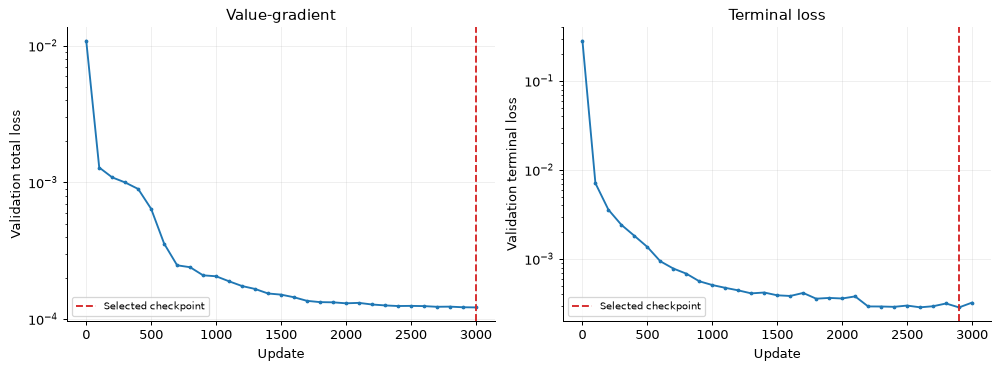

In [144]:
arithmetic_sources = {k: json.loads((arithmetic_dir / k / "report.json").read_text()) for k in arithmetic_keys}
table(["Model", "Parameters", "Selected / completed update", "Fit seconds", "Paired evaluation seconds", "Runtime"], [
    [arithmetic_names[k], arithmetic_models[k]["parameter_count"],
     f'{m["source"]["selected_step"]} / {m["source"]["completed_updates"]}',
     m["source"]["training_seconds"], m["source"]["evaluation_seconds"], m["source"]["training_runtime"]]
    for k in arithmetic_keys for m in [arithmetic_models[k]]])
table(["Task", "Process wall seconds", "Peak resident MiB", "Memory source", "System"], [
    [k, r["process_wall_seconds"], r["peak_resident_mib"], r["memory_source"], r["system"]]
    for k, r in arithmetic_report["resources"].items()])
table(["Budget quantity", "Value"], list(arithmetic_report["budget_projection"].items()) + [
    ("Controller peak resident MiB", arithmetic_report["controller_peak_resident_mib"]),
    ("Installed physical GiB", arithmetic_report["physical_memory_gib"]),
    ("Total pilot wall seconds", arithmetic_report["wall_seconds"])])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, k, objective in zip(axes, arithmetic_keys, ("validation_total", "validation_terminal")):
    h = arithmetic_sources[k]["history"]
    ax.semilogy([r["step"] for r in h], [r[objective] for r in h], marker="o", markersize=2)
    ax.axvline(arithmetic_models[k]["source"]["selected_step"], color="tab:red", linestyle="--", label="Selected checkpoint")
    ax.set(title=arithmetic_names[k], xlabel="Update", ylabel="Validation total loss" if k == "value_gradient" else "Validation terminal loss")
    ax.legend(fontsize=8)
plt.show()


The Sobol refinement and independent IID check assess the reference calculation. The IID coordinate differences share paths and are correlated. Their standardised differences should be read with the full table, including coordinates whose pointwise 95% intervals disagree. The four-combined-standard-error screen retained in the report is a diagnostic, with no claim of simultaneous coverage.

Initial price error, weight-scaled delta error, payoff mismatch and validation loss answer different questions. This pilot does not evaluate conditional arithmetic reference deltas on every simulated path, so it does not report an arithmetic path-risk RMSE. The next experiment-design step will fix the seed counts, time limits, case matrix and accuracy rules before confirmatory evaluation.


## 26. Twenty-five-asset development case

The locked arithmetic case has 25 spots of 100, strike 100, equal weights of 0.04, volatility 20%, no dividends, rate 3%, one year to expiry and pairwise correlation 0.30. Increasing dimension changes both the computation and diversification. The reported initial instantaneous relative variance is $\sigma^2[\rho+(1-\rho)/d]$. Arithmetic terminal relative variance separately uses the joint lognormal moments, so it is not equated with the geometric basket's log variance.

```bash
python -m bsde_pricing development-study
```

The command fits both formulations at development seeds 2026, 2027 and 2028 with the locked width, batch, grid and update budget. One independent reference is shared across the fits. Sobol and IID samples are processed in chunks of 4,096 states/pairs. The first declared reference level meeting both precision and agreement checks is retained. Final evaluation namespaces remain reserved.


In [145]:
development_dir = root / "scratch/runs/arithmetic_25_development"
development = json.loads((development_dir / "report.json").read_text())
development_reference = development["reference"]
development_keys = ("value_gradient", "terminal_loss")
development_names = {"value_gradient": "Value-gradient", "terminal_loss": "Terminal loss"}
table(["Study setting", "Value"], [("Status", development["status"]),
    ("Protocol fingerprint", development["specification_sha256"]), ("Seeds", development["seeds"]),
    ("Scope", development["scope"])] + list(development["basket_diagnostics"].items()))
table(["Reference allocation", "Task status", "Price / all scaled-delta budget", "Agreement screen", "Peak MiB"], [
    [r["power"], r["status"], r.get("error_budget_met"), r.get("agreement_met"), r.get("guard", {}).get("peak_resident_mib")]
    for r in development["reference_levels"]])
if development_reference is not None:
    table(["Reference quantity", "Value"], [("Price", development_reference["primary"]["price"]["estimate"]),
        ("Price 95% half-width", development_reference["reference_price_half_width"]),
        ("Largest scaled-delta half-width", max(development_reference["reference_scaled_delta_half_widths"])),
        ("Reference usable", development["reference_usable"]),
        ("Largest absolute method difference / combined SE", max(abs(r["difference_in_standard_errors"]) for r in development_reference["independent_method_agreement"]))])


Study setting,Value
Status,completed
Protocol fingerprint,bb1fa7f593af65920e988f11a0fd64082e5aa40abd7ebcbcc22ea5fe2f532a30
Seeds,"[2026, 2027, 2028]"
Scope,development only; final streams remain reserved
correlation_max_eigenvalue,8.2
correlation_min_eigenvalue,0.7
dimension,25
initial_basket,100
initial_instantaneous_relative_variance,0.01312
terminal_relative_variance,0.01322183


Reference allocation,Task status,Price / all scaled-delta budget,Agreement screen,Peak MiB
16,completed,"{'all_scaled_deltas': True, 'price': True}",True,142.9844


Reference quantity,Value
Price,6.132741
Price 95% half-width,0.00043547
Largest scaled-delta half-width,0.0004921414
Reference usable,True
Largest absolute method difference / combined SE,1.427402


## 27. Initial errors across all development seeds

The price band is 0.01 currency units and the coordinate band is 0.01 in $\Delta_i/w_i$. Error bars show only the shared numerical reference's pointwise 95% uncertainty. They do not quantify training-seed variability or provide simultaneous coverage. Each checkpoint uses its own validation objective. The plotted seeds remain separate, and all target classifications and task failures are retained in the tables.

The heatmap shows all 25 coordinate errors for all six selected models. The summary table reports the largest absolute weight-scaled delta error and the directional sensitivity $\sum_i\Delta_i$. Initial arithmetic-call bounds are $[0,w_i e^{-q_iT}]$. Passing these bounds supplies a weaker check than matching the independent delta reference.


Seed,Model,Task status,Selected / completed update,Fit seconds
2026,Terminal loss,completed,2900 / 3000,17.70812
2026,Value-gradient,completed,2900 / 3000,12.62252
2027,Terminal loss,completed,2500 / 3000,18.36235
2027,Value-gradient,completed,2900 / 3000,11.72815
2028,Terminal loss,completed,2800 / 3000,18.06662
2028,Value-gradient,completed,3000 / 3000,11.84261


Seed,Model,Price error,Price target,Max scaled-delta error,Delta classifications,Directional delta,Initial bound violations
2026,Value-gradient,0.001406649,within_target,0.2268274,"{'outside_target': 23, 'within_target': 2}",0.605,0
2026,Terminal loss,-0.02792348,outside_target,0.1652441,"{'outside_target': 23, 'unresolved_at_reference_precision': 1, 'within_target': 1}",0.6254541,0
2027,Value-gradient,0.005024636,within_target,0.1989361,"{'outside_target': 24, 'within_target': 1}",0.5617524,0
2027,Terminal loss,-0.01343619,outside_target,0.2228405,"{'outside_target': 22, 'within_target': 3}",0.6320214,0
2028,Value-gradient,0.04720704,outside_target,0.07709504,"{'outside_target': 21, 'within_target': 4}",0.6102096,0
2028,Terminal loss,0.03211951,outside_target,0.1601515,"{'outside_target': 22, 'within_target': 3}",0.6282994,0


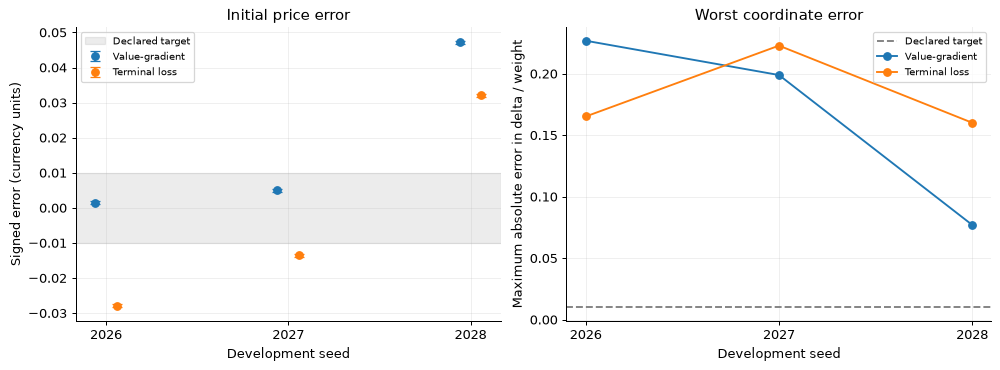

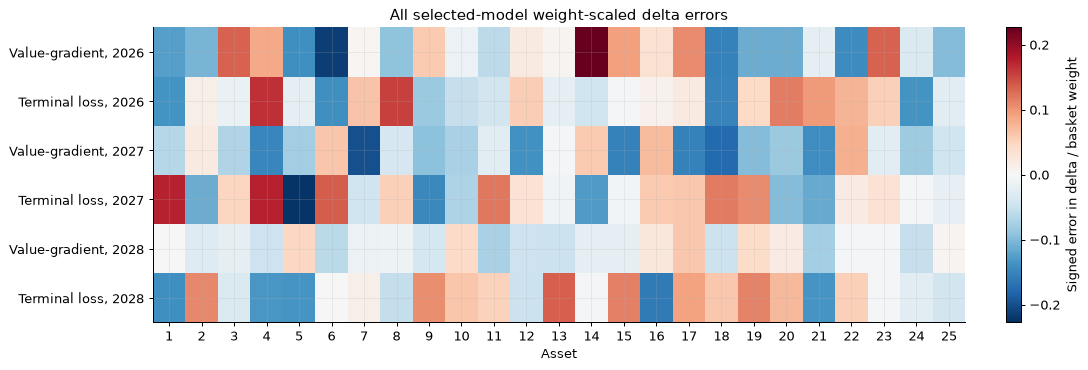

In [146]:
development_models = [(r["seed"], k, r["models"][k]) for r in development["runs"] if "models" in r for k in development_keys]
table(["Seed", "Model", "Task status", "Selected / completed update", "Fit seconds"], [
    [r["seed"], development_names[k], t["status"], f'{t.get("selected_step")} / {t.get("completed_updates")}', t.get("training_seconds")]
    for r in development["runs"] for k, t in r["tasks"].items()])
table(["Seed", "Model", "Price error", "Price target", "Max scaled-delta error", "Delta classifications", "Directional delta", "Initial bound violations"], [
    [seed, development_names[k], m["price_check"]["signed_error"], m["price_check"]["classification"],
     m["maximum_absolute_scaled_delta_error"],
     {c: sum(d["classification"] == c for d in m["scaled_delta_checks"]) for c in sorted(set(d["classification"] for d in m["scaled_delta_checks"]))},
     m["directional_delta"], m["initial_delta_bound_violations"]]
    for seed, k, m in development_models])
if development_models:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    axes[0].axhspan(-0.01, 0.01, color="grey", alpha=0.15, label="Declared target")
    axes[1].axhline(0.01, color="grey", linestyle="--", label="Declared target")
    for k, shift in zip(development_keys, (-0.06, 0.06)):
        rows = [(s, m) for s, kind, m in development_models if kind == k]
        axes[0].errorbar([s+shift for s, m in rows], [m["price_check"]["signed_error"] for s, m in rows],
                         yerr=development_reference["reference_price_half_width"], fmt="o", capsize=4, label=development_names[k])
        axes[1].plot([s for s, m in rows], [m["maximum_absolute_scaled_delta_error"] for s, m in rows], marker="o", label=development_names[k])
    axes[0].set(title="Initial price error", ylabel="Signed error (currency units)")
    axes[1].set(title="Worst coordinate error", ylabel="Maximum absolute error in delta / weight")
    for ax in axes:
        ax.set(xlabel="Development seed", xticks=development["seeds"])
        ax.legend(fontsize=8)
    plt.show()
    errors = np.asarray([[d["signed_error"] for d in m["scaled_delta_checks"]] for s, k, m in development_models])
    extent = max(float(np.max(np.abs(errors))), 0.01)
    fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
    shown = ax.imshow(errors, aspect="auto", cmap="RdBu_r", vmin=-extent, vmax=extent)
    ax.set(xticks=np.arange(25), xticklabels=np.arange(1, 26), xlabel="Asset",
           yticks=np.arange(len(development_models)), yticklabels=[f'{development_names[k]}, {s}' for s, k, m in development_models],
           title="All selected-model weight-scaled delta errors")
    fig.colorbar(shown, ax=ax, label="Signed error in delta / basket weight")
    plt.show()
else:
    print("Model comparisons are unavailable. Task failures remain in the saved report.")


## 28. Resource use and seed variation

Workers run sequentially with a 180-second fitting cap, 300-second total neural-worker wall cap and 2,048 MiB resident-memory limit. The parent samples RSS every 0.2 seconds and also checks the worker's reported lifetime peak. A breach retains its guard record and failure status. Completed reference and comparison workers have their own resource records. RSS includes imports and allocator retention, with controller memory recorded separately.

The summary retains each seed's error, mean, sample standard deviation and range. Three development seeds give a small descriptive stability sample. A precise reference, a small average price error or a passed bound check does not establish reliable coordinate risk. The common configuration transfers computationally only if its declared budgets complete. Numerical accuracy is assessed independently.


Model,Metric,Values,Mean,Sample standard deviation,Range
Terminal loss,maximum_absolute_scaled_delta_error,"[0.16524409618263977, 0.22284045622073265, 0.16015147429829513]",0.1827453,0.03481662,"(0.16015147429829513, 0.22284045622073265)"
Terminal loss,price_signed_error,"[-0.027923484051439296, -0.013436190771955125, 0.03211950672990227]",-0.003080056,0.03133253,"(-0.027923484051439296, 0.03211950672990227)"
Terminal loss,training_seconds,"[17.70811929111369, 18.362353750038892, 18.066618790850043]",18.0457,0.3276186,"(17.70811929111369, 18.362353750038892)"
Terminal loss,worker_wall_seconds_all_attempts,"[19.735166165977716, 20.270205500070006, 19.957127958070487]",19.9875,0.2688096,"(19.735166165977716, 20.270205500070006)"
Value-gradient,maximum_absolute_scaled_delta_error,"[0.22682737817007434, 0.198936066099972, 0.07709504259042688]",0.1676195,0.07962719,"(0.07709504259042688, 0.22682737817007434)"
Value-gradient,price_signed_error,"[0.0014066485813115648, 0.005024635579403913, 0.047207040952409685]",0.01787944,0.02546279,"(0.0014066485813115648, 0.047207040952409685)"
Value-gradient,training_seconds,"[12.622521582990885, 11.72815024992451, 11.842613416025415]",12.06443,0.4866995,"(11.72815024992451, 12.622521582990885)"
Value-gradient,worker_wall_seconds_all_attempts,"[14.589989208150655, 13.484240083023906, 13.611845167120919]",13.89536,0.6049421,"(13.484240083023906, 14.589989208150655)"


Seed,Model,Parameters,Diffusion condition,Max reconstruction residual,Worker wall seconds,Worker peak MiB
2026,Value-gradient,721,3.422614,1.118519e-15,14.58999,382.9531
2026,Terminal loss,16721,3.422614,1.151104e-15,19.73517,372.0781
2027,Value-gradient,721,3.422614,8.436965e-16,13.48424,442.4375
2027,Terminal loss,16721,3.422614,1.37327e-15,20.27021,367.5469
2028,Value-gradient,721,3.422614,1.48745e-15,13.61185,466.4531
2028,Terminal loss,16721,3.422614,5.147892e-16,19.95713,389.4844


Study resource,Value
Total wall seconds,107.2763
Controller peak resident MiB,210.1094
Installed GiB,8


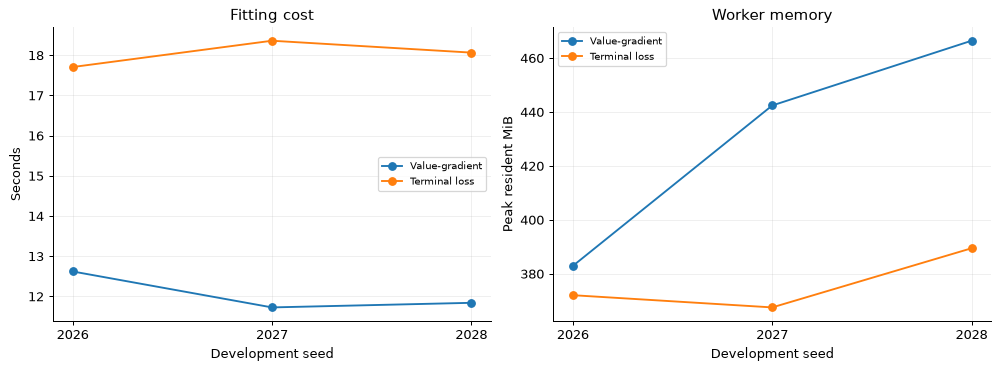

In [147]:
table(["Model", "Metric", "Values", "Mean", "Sample standard deviation", "Range"], [
    [development_names[k], metric, stats["values"], stats["mean"], stats["sample_standard_deviation"], (stats["min"], stats["max"])]
    for k, values in development["summary"].items() for metric, stats in values.items() if isinstance(stats, dict)])
table(["Seed", "Model", "Parameters", "Diffusion condition", "Max reconstruction residual", "Worker wall seconds", "Worker peak MiB"], [
    [seed, development_names[k], m["parameter_count"], m["initial"]["reconstruction"]["condition_number_max"],
     m["initial"]["reconstruction"]["max_absolute_reconstruction_residual"],
     next(r for r in development["runs"] if r["seed"] == seed)["tasks"][k]["guard"]["process_wall_seconds"],
     next(r for r in development["runs"] if r["seed"] == seed)["tasks"][k]["guard"]["peak_resident_mib"]]
    for seed, k, m in development_models])
table(["Study resource", "Value"], [("Total wall seconds", development["wall_seconds"]),
    ("Controller peak resident MiB", development["controller_peak_resident_mib"]), ("Installed GiB", development["physical_memory_gib"])])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for k in development_keys:
    rows = [(r["seed"], r["tasks"][k]) for r in development["runs"]]
    fits = [(s, t) for s, t in rows if "training_seconds" in t]
    memory = [(s, t) for s, t in rows if "guard" in t]
    if fits:
        axes[0].plot([s for s, t in fits], [t["training_seconds"] for s, t in fits], marker="o", label=development_names[k])
    if memory:
        axes[1].plot([s for s, t in memory], [t["guard"]["peak_resident_mib"] for s, t in memory], marker="o", label=development_names[k])
axes[0].set(title="Fitting cost", ylabel="Seconds")
axes[1].set(title="Worker memory", ylabel="Peak resident MiB")
for ax in axes:
    ax.set(xlabel="Development seed", xticks=development["seeds"])
    if ax.lines:
        ax.legend(fontsize=8)
plt.show()


## 29. Fifty-asset development and the dimension comparison

The next arithmetic case has equal weights of 0.02 and the same spots, strike, maturity, volatility, dividends, rate and correlation. All three development seeds and training settings are retained. The initial instantaneous relative variance falls to 0.01256, while correlation eigenvalues are 0.70 and 15.70. Dimension and diversification therefore change together.

```bash
python -m bsde_pricing development-study --case arithmetic-50
```

Reference streaming, refinement, checkpoint selection and process guards follow the existing study contract. These cells load the saved report. Final seed namespaces remain reserved. The dimension comparison shows every seed, with reference uncertainty separately retained in each report.


Setting,Value
Status,completed
Protocol fingerprint,bb1fa7f593af65920e988f11a0fd64082e5aa40abd7ebcbcc22ea5fe2f532a30
Training runtime,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"
correlation_max_eigenvalue,15.7
correlation_min_eigenvalue,0.7
dimension,50
initial_basket,100
initial_instantaneous_relative_variance,0.01256
terminal_relative_variance,0.01264706
weight_sum,1


Power,Reference task,Precision checks,Agreement screen,Worker peak MiB
16,completed,"{'all_scaled_deltas': True, 'price': True}",True,181.5312


Reference quantity,Value
Price,6.038314
Price 95% half-width,0.0007071966
Maximum scaled-delta half-width,0.0004281193
Usable,True


Seed,Model,Execution,Selected step,Price error,Price target,Max scaled-delta error,Initial bound violations
2026,Value-gradient,completed,2900,-0.0368748,outside_target,0.1633805,0
2026,Terminal loss,completed,3000,-0.01627344,outside_target,0.5763055,4
2027,Value-gradient,completed,2900,0.02644089,outside_target,0.1963944,0
2027,Terminal loss,completed,2900,-0.0410464,outside_target,0.4961151,3
2028,Value-gradient,completed,2900,0.04692211,outside_target,0.2320351,0
2028,Terminal loss,completed,2800,-0.03544812,outside_target,0.4399324,4


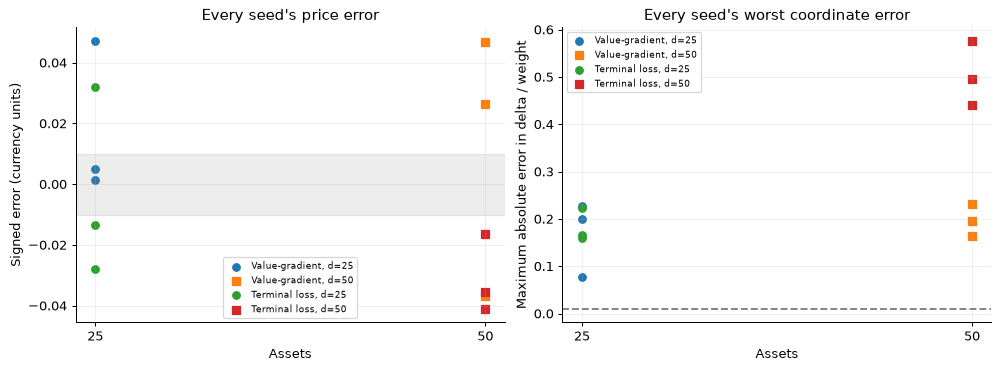

In [148]:
fifty_dir = root / "scratch/runs/arithmetic_50_development"
fifty = json.loads((fifty_dir / "report.json").read_text())
fifty_ref = fifty["reference"]
fifty_models = [(r["seed"], k, r["models"][k]) for r in fifty["runs"] if "models" in r for k in development_keys]
table(["Setting", "Value"], [("Status", fifty["status"]), ("Protocol fingerprint", fifty["specification_sha256"]), ("Training runtime", fifty_models[0][2]["source"]["training_runtime"] if fifty_models else "Unavailable")] + list(fifty["basket_diagnostics"].items()))
table(["Power", "Reference task", "Precision checks", "Agreement screen", "Worker peak MiB"], [
 [r["power"], r["status"], r.get("error_budget_met"), r.get("agreement_met"), r.get("guard",{}).get("peak_resident_mib")] for r in fifty["reference_levels"]])
if fifty_ref is not None:
 table(["Reference quantity", "Value"], [("Price", fifty_ref["primary"]["price"]["estimate"]),
  ("Price 95% half-width", fifty_ref["reference_price_half_width"]),
  ("Maximum scaled-delta half-width", max(fifty_ref["reference_scaled_delta_half_widths"])), ("Usable", fifty["reference_usable"])])
table(["Seed", "Model", "Execution", "Selected step", "Price error", "Price target", "Max scaled-delta error", "Initial bound violations"], [
 [s, development_names[k], m["source"]["status"], m["source"]["selected_step"], m["price_check"]["signed_error"],
  m["price_check"]["classification"], m["maximum_absolute_scaled_delta_error"], m["initial_delta_bound_violations"]] for s,k,m in fifty_models])
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for k in development_keys:
 for study,marker in ((development,"o"),(fifty,"s")):
  rows=[r["models"][k] for r in study["runs"] if "models" in r]
  d=study["basket_diagnostics"]["dimension"]
  axes[0].scatter([d]*len(rows),[m["price_check"]["signed_error"] for m in rows],marker=marker,label=f'{development_names[k]}, d={d}')
  axes[1].scatter([d]*len(rows),[m["maximum_absolute_scaled_delta_error"] for m in rows],marker=marker,label=f'{development_names[k]}, d={d}')
axes[0].axhspan(-0.01,0.01,color="grey",alpha=0.15)
axes[1].axhline(0.01,color="grey",linestyle="--")
axes[0].set(title="Every seed's price error",ylabel="Signed error (currency units)")
axes[1].set(title="Every seed's worst coordinate error",ylabel="Maximum absolute error in delta / weight")
for ax in axes:ax.set(xlabel="Assets",xticks=[25,50]);ax.legend(fontsize=7)
plt.show()


## 30. All fifty coordinate errors

Weight scaling retains a comparable coordinate criterion as raw deltas shrink with dimension. The colour scale covers every observed error and is centred at zero. The complete 50-coordinate values and pointwise reference intervals remain in the report. This view assesses initial risks. Conditional arithmetic path-risk RMSE remains unavailable.


Seed,Model,Within target,Outside target,Unresolved,Directional delta,Diffusion condition,Max reconstruction residual
2026,Value-gradient,3,45,2,0.6138403,4.735881,9.383684e-16
2026,Terminal loss,2,48,0,0.6435577,4.735881,1.879813e-15
2027,Value-gradient,3,46,1,0.609457,4.735881,9.773747e-16
2027,Terminal loss,4,46,0,0.6216022,4.735881,1.666028e-15
2028,Value-gradient,3,47,0,0.6164731,4.735881,1.5177e-15
2028,Terminal loss,2,48,0,0.6147296,4.735881,1.262802e-15


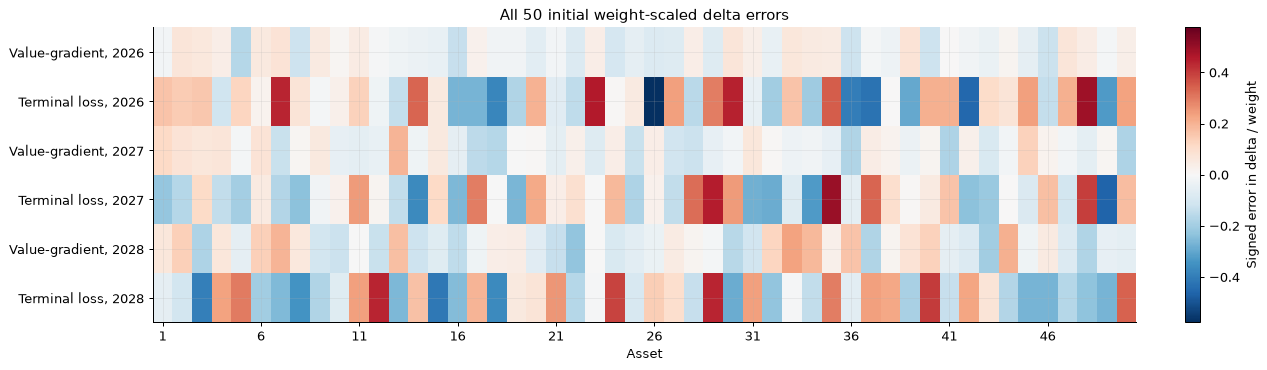

In [149]:
table(["Seed", "Model", "Within target", "Outside target", "Unresolved", "Directional delta", "Diffusion condition", "Max reconstruction residual"], [
 [s,development_names[k],sum(d["classification"]=="within_target" for d in m["scaled_delta_checks"]),
  sum(d["classification"]=="outside_target" for d in m["scaled_delta_checks"]),
  sum(d["classification"] not in ("within_target","outside_target") for d in m["scaled_delta_checks"]),
  m["directional_delta"],m["initial"]["reconstruction"]["condition_number_max"],m["initial"]["reconstruction"]["max_absolute_reconstruction_residual"]] for s,k,m in fifty_models])
if fifty_models:
 errors=np.asarray([[d["signed_error"] for d in m["scaled_delta_checks"]] for s,k,m in fifty_models])
 limit=max(float(np.max(np.abs(errors))),0.01)
 fig,ax=plt.subplots(figsize=(14,4),constrained_layout=True)
 shown=ax.imshow(errors,aspect="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)
 ax.set(xticks=np.arange(0,50,5),xticklabels=np.arange(1,51,5),xlabel="Asset",yticks=np.arange(len(fifty_models)),
        yticklabels=[f'{development_names[k]}, {s}' for s,k,m in fifty_models],title="All 50 initial weight-scaled delta errors")
 fig.colorbar(shown,ax=ax,label="Signed error in delta / weight")
 plt.show()


## 31. Training-update components and measured costs

The diagnostic uses path seed 2034 and model-initialisation seed 2026. It times two warmups and seven updates of fresh models with the declared batch, grid and width. Path sampling, objective forward evaluation, backward differentiation and the Adam step have separate timings. Value-gradient forward evaluation includes the automatic spot derivatives used in its loss. These short local measurements exclude imports and saved-fit evaluation. Diagnostic models supply no accuracy result or checkpoint choice.

Actual fitting time, worker wall time and peak resident memory remain separate. The profile helps explain the workload and does not turn component medians into an end-to-end speed claim. Failed tasks and resource caps remain visible in the report.


Seed,Model,Task status,Fit seconds,Paired evaluation seconds,Worker wall seconds,Peak MiB
2026,Terminal loss,completed,22.91487,0.1084553,25.16123,381.9219
2026,Value-gradient,completed,19.25374,0.2464189,21.18919,413.2812
2027,Terminal loss,completed,22.90548,0.1130967,24.86846,375.5938
2027,Value-gradient,completed,17.65902,0.1882245,19.5275,486.6719
2028,Terminal loss,completed,24.59563,0.1173815,26.67071,379.5469
2028,Value-gradient,completed,18.26889,0.2212843,20.20519,442.8594


Study cost,Value
Total wall seconds,146.0971
Controller peak MiB,210.1875
Installed GiB,8
Diagnostic status,completed


Model,Component,Median milliseconds,"All repetitions, milliseconds"
Terminal loss,backward,0.9772081,"[0.9772, 0.9523, 1.0151, 1.0194, 0.9692, 0.9649, 1.0263]"
Terminal loss,objective_forward,1.785,"[1.7988, 1.785, 1.7947, 1.7413, 1.7848, 1.7814, 1.8044]"
Terminal loss,optimizer_step,0.8974578,"[0.8975, 0.9091, 0.8862, 0.8885, 0.9219, 0.8922, 0.927]"
Terminal loss,sample_paths,2.601709,"[2.677, 2.6017, 2.5865, 2.6215, 2.5936, 2.5896, 2.615]"
Value-gradient,backward,0.8744162,"[0.9367, 0.8848, 0.8184, 0.9045, 0.7758, 0.848, 0.8744]"
Value-gradient,objective_forward,2.0885,"[2.293, 1.9236, 2.3246, 2.0885, 2.092, 1.9436, 1.9162]"
Value-gradient,optimizer_step,0.09854184,"[0.1085, 0.0985, 0.1114, 0.1033, 0.0945, 0.0941, 0.0915]"
Value-gradient,sample_paths,2.706667,"[2.7633, 2.7284, 2.7067, 2.8499, 2.6575, 2.6424, 2.6358]"


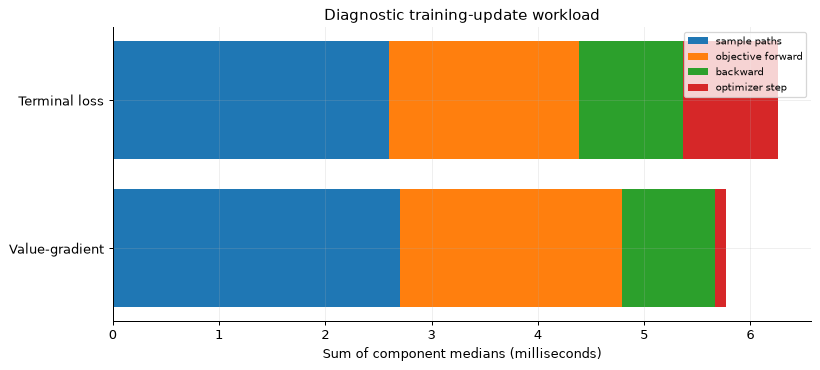

In [150]:
table(["Seed","Model","Task status","Fit seconds","Paired evaluation seconds","Worker wall seconds","Peak MiB"], [
 [r["seed"],development_names[k],t["status"],t.get("training_seconds"),t.get("evaluation_seconds"),
  t.get("guard",{}).get("process_wall_seconds"),t.get("guard",{}).get("peak_resident_mib")] for r in fifty["runs"] for k,t in r["tasks"].items()])
table(["Study cost","Value"],[("Total wall seconds",fifty["wall_seconds"]),("Controller peak MiB",fifty["controller_peak_resident_mib"]),
 ("Installed GiB",fifty["physical_memory_gib"]),("Diagnostic status",fifty["component_profile"]["task"]["status"])])
profile=fifty["component_profile"].get("timings")
if profile is not None:
 table(["Model","Component","Median milliseconds","All repetitions, milliseconds"],[
  [development_names[k],stage,1000*v,[round(x*1000,4) for x in m["seconds"][stage]]] for k,m in profile["models"].items() for stage,v in m["median_seconds"].items()])
 fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
 left=np.zeros(2)
 for stage in ("sample_paths","objective_forward","backward","optimizer_step"):
  values=np.asarray([1000*profile["models"][k]["median_seconds"][stage] for k in development_keys])
  ax.barh(np.arange(2),values,left=left,label=stage.replace("_"," "))
  left+=values
 ax.set(yticks=np.arange(2),yticklabels=[development_names[k] for k in development_keys],xlabel="Sum of component medians (milliseconds)",title="Diagnostic training-update workload")
 ax.legend(fontsize=8)
 plt.show()


## 32. Hundred-asset development and the dimension comparison

The next arithmetic case has equal weights of 0.01 and the same spots, strike, maturity, volatility, dividends, rate and correlation. All three development seeds and training settings are retained. The initial instantaneous relative variance falls to 0.01228, while correlation eigenvalues are 0.70 and 30.70. Dimension and diversification therefore change together.

```bash
python -m bsde_pricing development-study --case arithmetic-100
```

Reference streaming, refinement, checkpoint selection and process guards follow the existing study contract. These cells load the saved report. Final seed namespaces remain reserved. The dimension comparison shows every seed, with reference uncertainty separately retained in each report.

For equal spots, volatilities and weights, the instantaneous relative basket variance is $\sigma^2[\rho+(1-\rho)/d]$. It approaches $\sigma^2\rho$ as dimension grows. The common correlation component remains, so nominal dimension alone does not describe financial difficulty. A completed run does not establish accurate risks or dimensionality-independent convergence.


Setting,Value
Status,completed
Protocol fingerprint,bb1fa7f593af65920e988f11a0fd64082e5aa40abd7ebcbcc22ea5fe2f532a30
Training runtime,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"
correlation_max_eigenvalue,30.7
correlation_min_eigenvalue,0.7
dimension,100
initial_basket,100
initial_instantaneous_relative_variance,0.01228
terminal_relative_variance,0.01235967
weight_sum,1


Power,Reference task,Precision checks,Agreement screen,Worker peak MiB
16,completed,"{'all_scaled_deltas': True, 'price': True}",True,242.6562


Reference quantity,Value
Price,5.989534
Price 95% half-width,0.0006071032
Maximum scaled-delta half-width,0.0004572779
Usable,True


Seed,Model,Execution,Selected step,Price error,Price target,Max scaled-delta error,Initial bound violations
2026,Value-gradient,completed,2900,0.01194313,outside_target,0.2363567,0
2026,Terminal loss,completed,2700,0.03691709,outside_target,2.073864,49
2027,Value-gradient,completed,2600,0.02194924,outside_target,0.550986,1
2027,Terminal loss,completed,3000,0.003032156,within_target,1.502511,48
2028,Value-gradient,completed,2900,0.01542993,outside_target,0.4182477,1
2028,Terminal loss,completed,2800,0.04197627,outside_target,1.708511,36


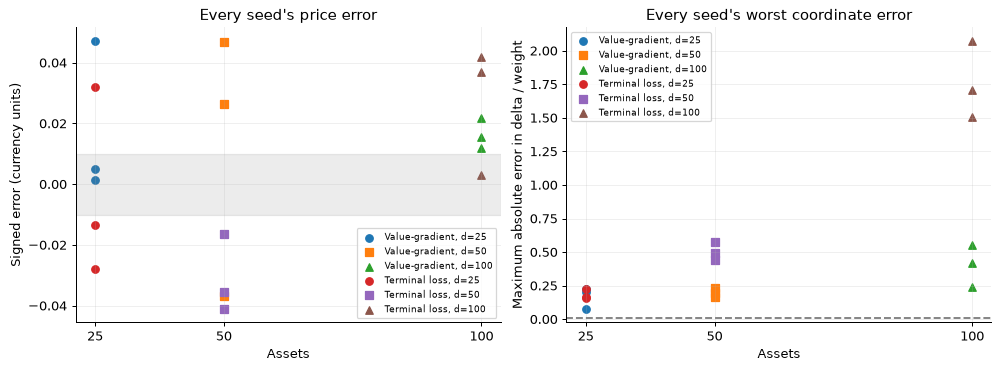

In [151]:
hundred_dir = root / "scratch/runs/arithmetic_100_development"
hundred = json.loads((hundred_dir / "report.json").read_text())
hundred_ref = hundred["reference"]
hundred_models = [(r["seed"], k, r["models"][k]) for r in hundred["runs"] if "models" in r for k in development_keys]
table(["Setting", "Value"], [("Status", hundred["status"]), ("Protocol fingerprint", hundred["specification_sha256"]), ("Training runtime", hundred_models[0][2]["source"]["training_runtime"] if hundred_models else "Unavailable")] + list(hundred["basket_diagnostics"].items()))
table(["Power", "Reference task", "Precision checks", "Agreement screen", "Worker peak MiB"], [
 [r["power"], r["status"], r.get("error_budget_met"), r.get("agreement_met"), r.get("guard",{}).get("peak_resident_mib")] for r in hundred["reference_levels"]])
if hundred_ref is not None:
 table(["Reference quantity", "Value"], [("Price", hundred_ref["primary"]["price"]["estimate"]),
  ("Price 95% half-width", hundred_ref["reference_price_half_width"]),
  ("Maximum scaled-delta half-width", max(hundred_ref["reference_scaled_delta_half_widths"])), ("Usable", hundred["reference_usable"])])
table(["Seed", "Model", "Execution", "Selected step", "Price error", "Price target", "Max scaled-delta error", "Initial bound violations"], [
 [s, development_names[k], m["source"]["status"], m["source"]["selected_step"], m["price_check"]["signed_error"],
  m["price_check"]["classification"], m["maximum_absolute_scaled_delta_error"], m["initial_delta_bound_violations"]] for s,k,m in hundred_models])
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for k in development_keys:
 for study,marker in ((development,"o"),(fifty,"s"),(hundred,"^")):
  rows=[r["models"][k] for r in study["runs"] if "models" in r]
  d=study["basket_diagnostics"]["dimension"]
  axes[0].scatter([d]*len(rows),[m["price_check"]["signed_error"] for m in rows],marker=marker,label=f'{development_names[k]}, d={d}')
  axes[1].scatter([d]*len(rows),[m["maximum_absolute_scaled_delta_error"] for m in rows],marker=marker,label=f'{development_names[k]}, d={d}')
axes[0].axhspan(-0.01,0.01,color="grey",alpha=0.15)
axes[1].axhline(0.01,color="grey",linestyle="--")
axes[0].set(title="Every seed's price error",ylabel="Signed error (currency units)")
axes[1].set(title="Every seed's worst coordinate error",ylabel="Maximum absolute error in delta / weight")
for ax in axes:ax.set(xlabel="Assets",xticks=[25,50,100]);ax.legend(fontsize=7)
plt.show()


## 33. All hundred coordinate errors

Weight scaling retains a comparable coordinate criterion as raw deltas shrink with dimension. The colour scale covers every observed error and is centred at zero. The complete 100-coordinate values and pointwise reference intervals remain in the report. This view assesses initial risks. Conditional arithmetic path-risk RMSE remains unavailable.


Seed,Model,Within target,Outside target,Unresolved,Directional delta,Diffusion condition,Max reconstruction residual
2026,Value-gradient,10,89,1,0.6220279,6.622473,1.880325e-15
2026,Terminal loss,1,99,0,0.6308528,6.622473,1.925197e-15
2027,Value-gradient,3,97,0,0.6456591,6.622473,3.131648e-15
2027,Terminal loss,0,100,0,0.6385646,6.622473,2.559894e-15
2028,Value-gradient,6,94,0,0.6358711,6.622473,1.788189e-15
2028,Terminal loss,2,98,0,0.6352575,6.622473,1.823691e-15


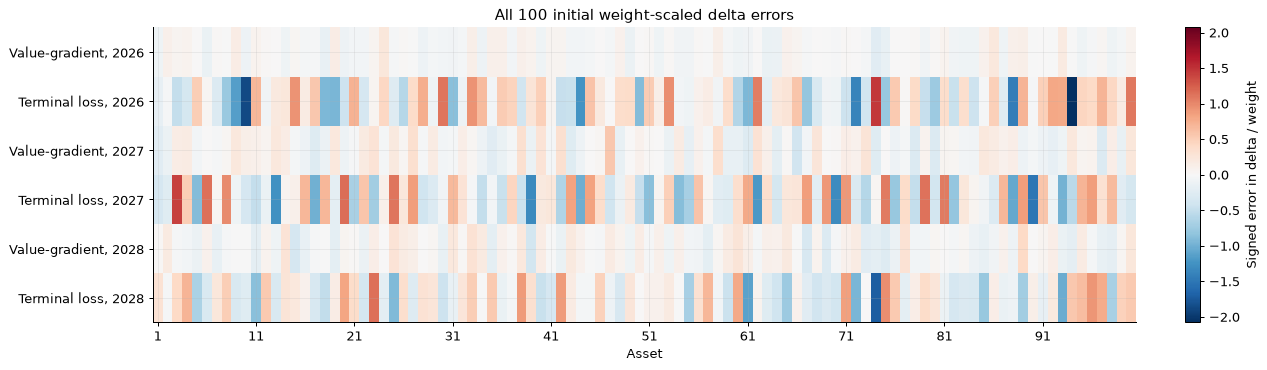

In [152]:
table(["Seed", "Model", "Within target", "Outside target", "Unresolved", "Directional delta", "Diffusion condition", "Max reconstruction residual"], [
 [s,development_names[k],sum(d["classification"]=="within_target" for d in m["scaled_delta_checks"]),
  sum(d["classification"]=="outside_target" for d in m["scaled_delta_checks"]),
  sum(d["classification"] not in ("within_target","outside_target") for d in m["scaled_delta_checks"]),
  m["directional_delta"],m["initial"]["reconstruction"]["condition_number_max"],m["initial"]["reconstruction"]["max_absolute_reconstruction_residual"]] for s,k,m in hundred_models])
if hundred_models:
 errors=np.asarray([[d["signed_error"] for d in m["scaled_delta_checks"]] for s,k,m in hundred_models])
 limit=max(float(np.max(np.abs(errors))),0.01)
 fig,ax=plt.subplots(figsize=(14,4),constrained_layout=True)
 shown=ax.imshow(errors,aspect="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)
 ax.set(xticks=np.arange(0,100,10),xticklabels=np.arange(1,101,10),xlabel="Asset",yticks=np.arange(len(hundred_models)),
        yticklabels=[f'{development_names[k]}, {s}' for s,k,m in hundred_models],title="All 100 initial weight-scaled delta errors")
 fig.colorbar(shown,ax=ax,label="Signed error in delta / weight")
 plt.show()


## 34. Training-update components and measured costs

The diagnostic uses path seed 2034 and model-initialisation seed 2026. It times two warmups and seven updates of fresh models with the declared batch, grid and width. Path sampling, objective forward evaluation, backward differentiation and the Adam step have separate timings. Value-gradient forward evaluation includes the automatic spot derivatives used in its loss. These short local measurements exclude imports and saved-fit evaluation. Diagnostic models supply no accuracy result or checkpoint choice.

Actual fitting time, worker wall time and peak resident memory remain separate. The profile helps explain the workload and does not turn component medians into an end-to-end speed claim. Failed tasks and resource caps remain visible in the report.


Seed,Model,Task status,Fit seconds,Paired evaluation seconds,Worker wall seconds,Peak MiB
2026,Terminal loss,completed,41.37474,0.2183227,43.5027,554.875
2026,Value-gradient,completed,41.72597,0.3841659,43.73876,582.2812
2027,Terminal loss,completed,41.72364,0.3069242,44.17292,427.8281
2027,Value-gradient,completed,38.92999,0.3646463,40.96722,566.3906
2028,Terminal loss,completed,39.88197,0.2189115,42.10508,492.5312
2028,Value-gradient,completed,38.30883,0.3920895,40.47977,496.4688


Study cost,Value
Total wall seconds,266.7802
Controller peak MiB,211.7344
Installed GiB,8
Diagnostic status,completed


Model,Component,Median milliseconds,"All repetitions, milliseconds"
Terminal loss,backward,1.186333,"[1.2706, 1.1556, 1.1864, 1.1817, 1.1863, 1.1625, 1.2326]"
Terminal loss,objective_forward,2.771917,"[2.9035, 2.7719, 2.7768, 2.7428, 2.7581, 2.7347, 3.0698]"
Terminal loss,optimizer_step,0.936917,"[0.9493, 0.9333, 0.9412, 0.9363, 0.9369, 0.9276, 0.97]"
Terminal loss,sample_paths,6.405708,"[6.504, 6.3799, 6.4057, 6.3957, 6.4049, 6.4683, 6.8867]"
Value-gradient,backward,1.50725,"[2.7628, 1.5181, 1.4273, 1.5072, 1.4285, 1.5015, 1.5233]"
Value-gradient,objective_forward,3.461833,"[4.2855, 3.523, 3.3593, 3.4069, 3.4377, 3.5486, 3.4618]"
Value-gradient,optimizer_step,0.1124172,"[0.1234, 0.1135, 0.1124, 0.1079, 0.1112, 0.1144, 0.1068]"
Value-gradient,sample_paths,6.397042,"[6.6048, 6.397, 6.7177, 6.4539, 6.3833, 6.1494, 6.3026]"


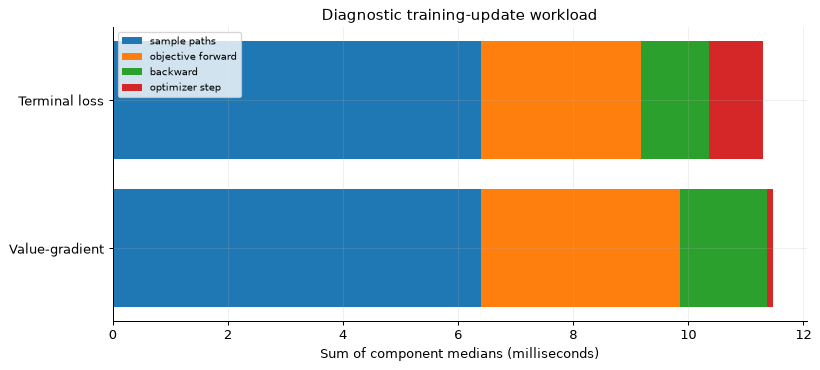

In [153]:
table(["Seed","Model","Task status","Fit seconds","Paired evaluation seconds","Worker wall seconds","Peak MiB"], [
 [r["seed"],development_names[k],t["status"],t.get("training_seconds"),t.get("evaluation_seconds"),
  t.get("guard",{}).get("process_wall_seconds"),t.get("guard",{}).get("peak_resident_mib")] for r in hundred["runs"] for k,t in r["tasks"].items()])
table(["Study cost","Value"],[("Total wall seconds",hundred["wall_seconds"]),("Controller peak MiB",hundred["controller_peak_resident_mib"]),
 ("Installed GiB",hundred["physical_memory_gib"]),("Diagnostic status",hundred["component_profile"]["task"]["status"])])
profile=hundred["component_profile"].get("timings")
if profile is not None:
 table(["Model","Component","Median milliseconds","All repetitions, milliseconds"],[
  [development_names[k],stage,1000*v,[round(x*1000,4) for x in m["seconds"][stage]]] for k,m in profile["models"].items() for stage,v in m["median_seconds"].items()])
 fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
 left=np.zeros(2)
 for stage in ("sample_paths","objective_forward","backward","optimizer_step"):
  values=np.asarray([1000*profile["models"][k]["median_seconds"][stage] for k in development_keys])
  ax.barh(np.arange(2),values,left=left,label=stage.replace("_"," "))
  left+=values
 ax.set(yticks=np.arange(2),yticklabels=[development_names[k] for k in development_keys],xlabel="Sum of component medians (milliseconds)",title="Diagnostic training-update workload")
 ax.legend(fontsize=8)
 plt.show()


## 35. Time-grid refinement at fixed training budget

The declared ten-asset arithmetic case is held fixed at 10, 20 and 40 intervals. Each grid uses both solvers and development seeds 2026, 2027 and 2028, for 18 fits. A shared independent terminal reference is independent of the path grid. Final streams remain reserved.

```bash
python -m bsde_pricing grid-study
```

Exact GBM transitions remove Euler bias from forward sampling. The grid still discretises the stochastic integral and, for value-gradient, the local BSDE constraints. With $\Delta t=T/M$, smaller steps do not guarantee that a finite network trained for 3,000 updates has smaller price or Greek error. Terminal loss has a separate control network per later date, so its parameter count grows with $M$; the value-gradient network remains shared. The seed labels repeat across grids, but the Brownian paths are not coupled across resolutions. Lines connect seed labels descriptively, without a paired Monte Carlo error interpretation.

Pointwise reference uncertainty is shown around each price error. The shared reference makes these uncertainties common across fits. The independent error targets, rather than raw losses, determine the accuracy classifications.


Study,Value
Status,completed
Scheduled fits,18
Protocol fingerprint,bb1fa7f593af65920e988f11a0fd64082e5aa40abd7ebcbcc22ea5fe2f532a30
Reference usable,True
Training runtime,"{'device': 'cpu', 'dtype': 'torch.float64', 'numpy': '2.5.4', 'python': '3.12.16', 'system': 'macOS-27.0.1-arm64-arm-64bit', 'torch': '2.15.0'}"


Power,Task status,Precision,Agreement,Reference peak MiB
16,completed,"{'all_scaled_deltas': True, 'price': True}",True,118.5781


Reference,Value
Price,6.406184
Price 95% half-width,0.0003619206
Maximum scaled-delta half-width,0.0003368865


Intervals,Seed,Model,Price error,Price target,Max scaled-delta error,Initial bound violations
10,2026,Value-gradient,-0.04854929,outside_target,0.09369262,0
10,2026,Terminal loss,-0.01217574,outside_target,0.09040883,0
10,2027,Value-gradient,0.1353703,outside_target,0.06382426,0
10,2027,Terminal loss,0.01645542,outside_target,0.09010849,0
10,2028,Value-gradient,-0.2108966,outside_target,0.09299963,0
10,2028,Terminal loss,-0.007264938,within_target,0.07898024,0
20,2026,Value-gradient,0.006980552,within_target,0.1102726,0
20,2026,Terminal loss,-0.02390259,outside_target,0.07616355,0
20,2027,Value-gradient,0.1430739,outside_target,0.1032257,0
20,2027,Terminal loss,0.06122804,outside_target,0.05538675,0


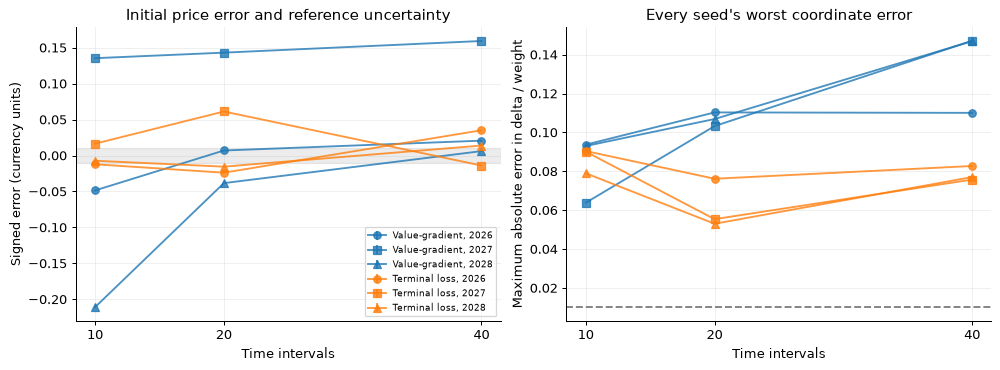

In [154]:
grid_dir = root / "scratch/runs/arithmetic_10_grid_study"
grid_study = json.loads((grid_dir / "report.json").read_text())
grid_ref = grid_study["reference"]
grid_models = [(g["n_steps"], r["seed"], k, r["models"][k]) for g in grid_study["grids"]
               for r in g["runs"] if "models" in r for k in development_keys]
table(["Study", "Value"], [("Status", grid_study["status"]), ("Scheduled fits", grid_study["scheduled_fits"]),
 ("Protocol fingerprint", grid_study["specification_sha256"]), ("Reference usable", grid_study["reference_usable"]),
 ("Training runtime",grid_models[0][3]["source"]["training_runtime"] if grid_models else "Unavailable")])
table(["Power", "Task status", "Precision", "Agreement", "Reference peak MiB"], [
 [r["power"],r["status"],r.get("error_budget_met"),r.get("agreement_met"),r.get("guard",{}).get("peak_resident_mib")]
 for r in grid_study["reference_levels"]])
if grid_ref is not None:
 table(["Reference", "Value"], [("Price",grid_ref["primary"]["price"]["estimate"]),
  ("Price 95% half-width",grid_ref["reference_price_half_width"]),
  ("Maximum scaled-delta half-width",max(grid_ref["reference_scaled_delta_half_widths"]))])
table(["Intervals","Seed","Model","Price error","Price target","Max scaled-delta error","Initial bound violations"], [
 [steps,seed,development_names[k],m["price_check"]["signed_error"],m["price_check"]["classification"],
  m["maximum_absolute_scaled_delta_error"],m["initial_delta_bound_violations"]] for steps,seed,k,m in grid_models])
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for k,color in zip(development_keys,("tab:blue","tab:orange")):
 for seed,marker in zip(grid_study["seeds"],("o","s","^")):
  rows=[(steps,m) for steps,s,kind,m in grid_models if s==seed and kind==k]
  if not rows:continue
  xs=[steps for steps,m in rows]
  half=grid_ref["reference_price_half_width"]
  axes[0].errorbar(xs,[m["price_check"]["signed_error"] for steps,m in rows],yerr=half,
                   color=color,marker=marker,alpha=0.8,label=f'{development_names[k]}, {seed}')
  axes[1].plot(xs,[m["maximum_absolute_scaled_delta_error"] for steps,m in rows],color=color,marker=marker,alpha=0.8)
axes[0].axhspan(-0.01,0.01,color="grey",alpha=0.15)
axes[1].axhline(0.01,color="grey",linestyle="--")
axes[0].set(title="Initial price error and reference uncertainty",ylabel="Signed error (currency units)")
axes[1].set(title="Every seed's worst coordinate error",ylabel="Maximum absolute error in delta / weight")
for ax in axes:ax.set(xlabel="Time intervals",xticks=grid_study["grid_steps"])
if grid_models:axes[0].legend(fontsize=7)
plt.show()


## 36. Coordinate risks across the grids

Every ten-coordinate error is retained for each seed and formulation. The heatmap uses one symmetric colour scale across all rows. Passing a financial bound is weaker than matching the independent delta target. Conditional arithmetic path-risk references remain unavailable; these comparisons concern the initial state only.


Intervals,Seed,Model,Within target,Outside target,Unresolved,Directional delta,Bound violations
10,2026,Value-gradient,0,10,0,0.6139297,0
10,2026,Terminal loss,3,7,0,0.6182818,0
10,2027,Value-gradient,2,8,0,0.6039926,0
10,2027,Terminal loss,1,9,0,0.6154935,0
10,2028,Value-gradient,0,10,0,0.5792978,0
10,2028,Terminal loss,2,8,0,0.6254055,0
20,2026,Value-gradient,0,10,0,0.6142977,0
20,2026,Terminal loss,2,8,0,0.6163725,0
20,2027,Value-gradient,2,8,0,0.5958518,0
20,2027,Terminal loss,3,7,0,0.6239183,0


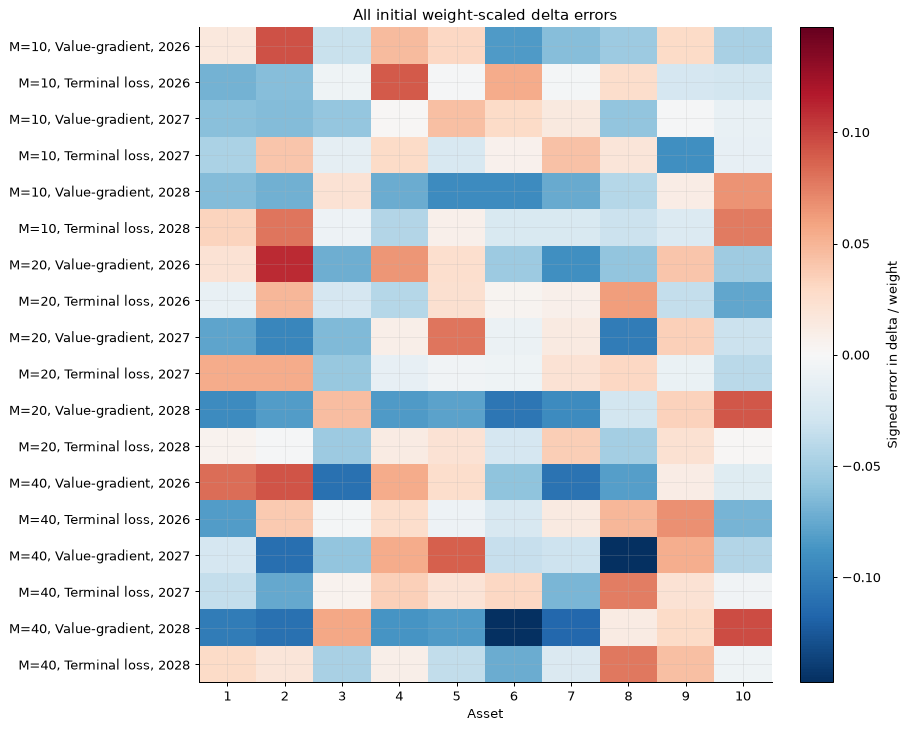

In [155]:
table(["Intervals","Seed","Model","Within target","Outside target","Unresolved","Directional delta","Bound violations"], [
 [steps,seed,development_names[k],sum(c["classification"]=="within_target" for c in m["scaled_delta_checks"]),
  sum(c["classification"]=="outside_target" for c in m["scaled_delta_checks"]),
  sum(c["classification"] not in ("within_target","outside_target") for c in m["scaled_delta_checks"]),
  m["directional_delta"],m["initial_delta_bound_violations"]] for steps,seed,k,m in grid_models])
if grid_models:
 errors=np.asarray([[c["signed_error"] for c in m["scaled_delta_checks"]] for steps,seed,k,m in grid_models])
 limit=max(0.01,float(np.max(np.abs(errors))))
 fig,ax=plt.subplots(figsize=(10,8),constrained_layout=True)
 shown=ax.imshow(errors,aspect="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)
 ax.set(xticks=np.arange(10),xticklabels=np.arange(1,11),xlabel="Asset",yticks=np.arange(len(grid_models)),
        yticklabels=[f'M={steps}, {development_names[k]}, {seed}' for steps,seed,k,m in grid_models],
        title="All initial weight-scaled delta errors")
 fig.colorbar(shown,ax=ax,label="Signed error in delta / weight")
 plt.show()


## 37. Grid-dependent work and validation objectives

All fits retain the same maximum update count, width, batch and learning-rate schedule. Increasing grid resolution changes work per update and the terminal solver's parameter count. Fits and checkpoint selection are repeated independently at every grid; no numerical reference selects a checkpoint or a preferred grid.

The table retains each selected validation objective. Value-gradient uses a sum of squared local discounted residuals plus terminal mismatch. Terminal loss uses squared propagated terminal mismatch. Their magnitudes are not comparable between formulations, and a smaller local sum across grids is not a convergence result. Independent price/delta errors and seed spread remain the relevant evidence.


Intervals,Seed,Model,Execution,Updates,Selected,Validation objective,Fit seconds,Worker wall seconds,Peak MiB
10,2026,Terminal loss,completed,3000,2500,0.0002729169,10.63796,12.41929,302.6719
10,2026,Value-gradient,completed,3000,2800,0.0001478869,7.145507,8.848305,354.7656
10,2027,Terminal loss,completed,3000,2700,0.0003452167,11.54574,13.84128,308.5781
10,2027,Value-gradient,completed,3000,3000,0.0001713283,7.581965,9.631802,295.6406
10,2028,Terminal loss,completed,3000,2700,0.0003233191,10.80676,13.17753,298.6719
10,2028,Value-gradient,completed,3000,3000,0.0001731737,7.391007,9.845256,299.2188
20,2026,Terminal loss,completed,3000,2600,0.000306882,19.0992,21.08795,307.5
20,2026,Value-gradient,completed,3000,3000,0.000101952,12.32903,14.48926,375.2344
20,2027,Terminal loss,completed,3000,2700,0.0002663999,19.05037,20.97718,310.75
20,2027,Value-gradient,completed,3000,3000,0.0001023564,10.44136,12.18412,401


Intervals,Model,Parameter counts,Compared seeds,Price error range,Worst scaled-delta error range
10,Terminal loss,[5573],3,"[-0.012175736421229821, 0.016455419654500147]","[0.07898024233583378, 0.09040882954279142]"
10,Value-gradient,[481],3,"[-0.21089664604280056, 0.13537028949784524]","[0.06382425535123887, 0.09369261754300695]"
20,Terminal loss,[11753],3,"[-0.023902589069911606, 0.0612280374657761]","[0.05301866683566567, 0.07616355368894594]"
20,Value-gradient,[481],3,"[-0.03837356385802604, 0.14307388537007526]","[0.10322573015692914, 0.11027262434653809]"
40,Terminal loss,[24113],3,"[-0.013907316517828505, 0.03513856528494408]","[0.07574115111014884, 0.08271798381550205]"
40,Value-gradient,[481],3,"[0.006098982882277504, 0.15928518728519858]","[0.11004392873692606, 0.14713588090416582]"


Study cost,Value
Total wall seconds,360.4678
Controller peak MiB,213.8125
Installed GiB,8


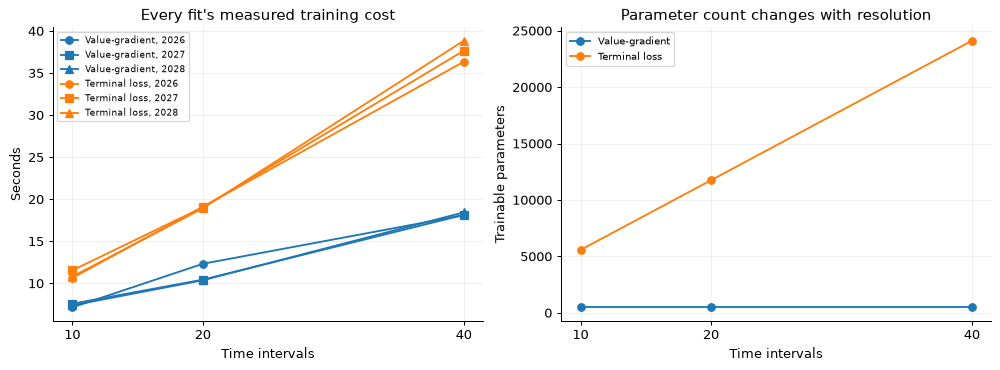

In [156]:
table(["Intervals","Seed","Model","Execution","Updates","Selected","Validation objective","Fit seconds","Worker wall seconds","Peak MiB"], [
 [g["n_steps"],r["seed"],development_names[k],t["status"],t.get("completed_updates"),t.get("selected_step"),
  t.get("selected_validation_objective"),t.get("training_seconds"),t.get("guard",{}).get("process_wall_seconds"),
  t.get("guard",{}).get("peak_resident_mib")] for g in grid_study["grids"] for r in g["runs"] for k,t in r["tasks"].items()])
table(["Intervals","Model","Parameter counts","Compared seeds","Price error range","Worst scaled-delta error range"], [
 [g["n_steps"],development_names[k],sorted({m["parameter_count"] for steps,seed,kind,m in grid_models if steps==g["n_steps"] and kind==k}),
  s["compared_runs"],[s["price_signed_error"]["min"],s["price_signed_error"]["max"]],
  [s["maximum_absolute_scaled_delta_error"]["min"],s["maximum_absolute_scaled_delta_error"]["max"]]]
 for g in grid_study["grids"] for k,s in g["summary"].items()])
table(["Study cost","Value"],[("Total wall seconds",grid_study["wall_seconds"]),
 ("Controller peak MiB",grid_study["controller_peak_resident_mib"]),("Installed GiB",grid_study["physical_memory_gib"])])
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for k,color in zip(development_keys,("tab:blue","tab:orange")):
 for seed,marker in zip(grid_study["seeds"],("o","s","^")):
  rows=[(g["n_steps"],r["tasks"][k]) for g in grid_study["grids"] for r in g["runs"]
        if r["seed"]==seed and "training_seconds" in r["tasks"][k]]
  axes[0].plot([steps for steps,t in rows],[t["training_seconds"] for steps,t in rows],color=color,marker=marker,
               label=f'{development_names[k]}, {seed}')
 counts=sorted({(steps,m["parameter_count"]) for steps,seed,kind,m in grid_models if kind==k})
 axes[1].plot([steps for steps,count in counts],[count for steps,count in counts],color=color,marker="o",label=development_names[k])
axes[0].set(title="Every fit's measured training cost",ylabel="Seconds")
axes[1].set(title="Parameter count changes with resolution",ylabel="Trainable parameters")
for ax in axes:ax.set(xlabel="Time intervals",xticks=grid_study["grid_steps"])
axes[0].legend(fontsize=7)
if grid_models:axes[1].legend(fontsize=8)
plt.show()


## 38. Financial stresses and initial Greeks

The four locked ten-asset arithmetic stresses change one input at a time: strike 90, strike 110, maturity 0.25 years, or equicorrelation 0.80. Both solvers use development seeds 2026-2028, the 16-interval base grid and 3,000 updates. These 24 fits add no tuning and draw no reserved final streams.

```bash
python -m bsde_pricing stress-study
```

Independent prices and every coordinate delta retain the original targets and numerical reference uncertainty. Errors divided by basket weights expose sensitivity errors that a small physical coordinate delta could hide. Each financial case has its own independent reference and resource records. This is a selected stress study, without a full Cartesian product or a matched baseline effect estimate.


Study,Value
Status,completed
Scheduled fits,24
Protocol fingerprint,bb1fa7f593af65920e988f11a0fd64082e5aa40abd7ebcbcc22ea5fe2f532a30
Scope,development seeds only; four single-factor stresses; existing asymmetric analytical fits; no tuning


Case,Reference usable,Price,Price half-width,Largest scaled-delta half-width,Eigenvalue range
arithmetic-10-strike-90,True,13.42282,0.0003843707,0.0003036774,"[0.6999999999999992, 3.700000000000001]"
arithmetic-10-strike-110,True,2.349227,0.000580538,0.0003598245,"[0.6999999999999992, 3.700000000000001]"
arithmetic-10-short,True,2.80984,0.0001266821,0.0002683028,"[0.6999999999999992, 3.700000000000001]"
arithmetic-10-correlation-80,True,8.683757,7.869621e-05,0.0001878268,"[0.1999999999999986, 8.2]"


Case,Seed,Model,Price error,Price target,Worst scaled-delta error,All deltas pass,Bounds,Diffusion condition
arithmetic-10-strike-90,2026,Value-gradient,0.02576634,outside_target,0.1230793,False,0,2.299068
arithmetic-10-strike-90,2026,Terminal loss,-0.002705123,within_target,0.07321667,False,0,2.299068
arithmetic-10-strike-90,2027,Value-gradient,-0.05203049,outside_target,0.1246422,False,0,2.299068
arithmetic-10-strike-90,2027,Terminal loss,-0.01821904,outside_target,0.06880743,False,0,2.299068
arithmetic-10-strike-90,2028,Value-gradient,-0.02930104,outside_target,0.1324523,False,0,2.299068
arithmetic-10-strike-90,2028,Terminal loss,-0.003025298,within_target,0.07802348,False,0,2.299068
arithmetic-10-strike-110,2026,Value-gradient,0.1156241,outside_target,0.0924767,False,0,2.299068
arithmetic-10-strike-110,2026,Terminal loss,-0.008616213,within_target,0.09066941,False,0,2.299068
arithmetic-10-strike-110,2027,Value-gradient,-0.08290783,outside_target,0.1180779,False,0,2.299068
arithmetic-10-strike-110,2027,Terminal loss,-0.01907133,outside_target,0.07211848,False,0,2.299068


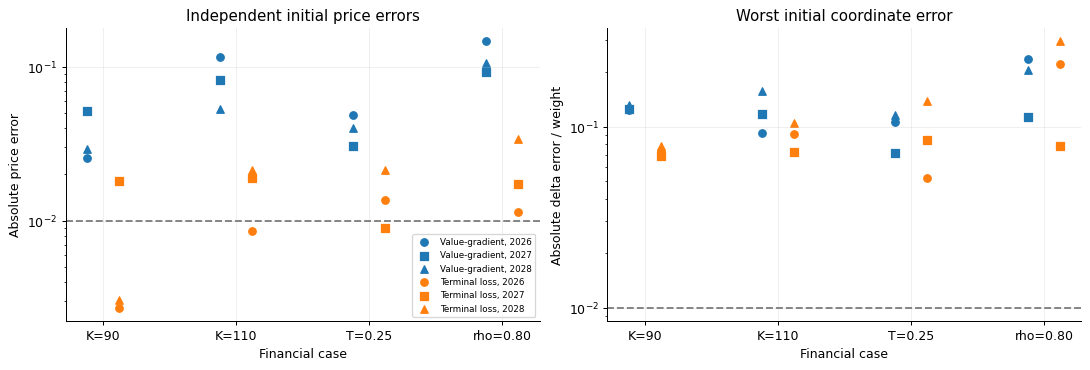

In [40]:
stress_dir = root / "scratch/runs/greek_stress_study"
stress = json.loads((stress_dir / "report.json").read_text())
stress_names = [c["case"] for c in stress["cases"]]
stress_models = [(i,c,r,k,r["models"][k]) for i,c in enumerate(stress["cases"])
                 for r in c["study"]["runs"] if "models" in r for k in development_keys]
table(["Study","Value"], [("Status",stress["status"]),("Scheduled fits",stress["scheduled_fits"]),
 ("Protocol fingerprint",stress["specification_sha256"]),("Scope",stress["scope"])])
table(["Case","Reference usable","Price","Price half-width","Largest scaled-delta half-width","Eigenvalue range"], [
 [c["case"],c["study"]["reference_usable"],c["study"]["reference"]["primary"]["price"]["estimate"],
 c["study"]["reference"]["reference_price_half_width"],max(c["study"]["reference"]["reference_scaled_delta_half_widths"]),
 [c["study"]["basket_diagnostics"]["correlation_min_eigenvalue"],c["study"]["basket_diagnostics"]["correlation_max_eigenvalue"]]]
 for c in stress["cases"] if c["study"]["reference"] is not None])
table(["Case","Seed","Model","Price error","Price target","Worst scaled-delta error","All deltas pass","Bounds","Diffusion condition"], [
 [c["case"],r["seed"],development_names[k],m["price_check"]["signed_error"],m["price_check"]["classification"],
 m["maximum_absolute_scaled_delta_error"],all(d["classification"]=="within_target" for d in m["scaled_delta_checks"]),
 m["initial_delta_bound_violations"],m["initial"]["reconstruction"]["condition_number_max"]]
 for i,c,r,k,m in stress_models])
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for k,color in zip(development_keys,("tab:blue","tab:orange")):
 for seed,marker in zip(stress["specification"]["development_seeds"],("o","s","^")):
  rows=[(i,m) for i,c,r,kind,m in stress_models if kind==k and r["seed"]==seed]
  offset=(-0.12 if k=="value_gradient" else 0.12)
  axes[0].scatter([i+offset for i,m in rows],[abs(m["price_check"]["signed_error"]) for i,m in rows],color=color,marker=marker,label=f"{development_names[k]}, {seed}")
  axes[1].scatter([i+offset for i,m in rows],[m["maximum_absolute_scaled_delta_error"] for i,m in rows],color=color,marker=marker)
for ax in axes:
 ax.axhline(0.01,color="grey",linestyle="--")
 ax.set(xticks=range(len(stress_names)),xticklabels=["K=90","K=110","T=0.25","rho=0.80"],yscale="log",xlabel="Financial case")
axes[0].set(title="Independent initial price errors",ylabel="Absolute price error")
axes[1].set(title="Worst initial coordinate error",ylabel="Absolute delta error / weight")
axes[0].legend(fontsize=7)
plt.show()


## 39. Coordinate and directional sensitivity

For a spot direction $v$, the initial directional delta is $v^\top\Delta$. Its reference uncertainty is computed across whole scramble-level projections, preserving covariance between coordinates. Summing separate coordinate standard errors would lose that covariance. The aggregate target is $0.01\sum_iw_i|v_i|$, implied by the weight-scaled coordinate targets.

Two directions are retained: a parallel one-unit shift of every spot, and one coordinate (the smallest-weight coordinate in the asymmetric case). A good aggregate result can coexist with bad coordinate errors through cancellation. Financial bound checks and diffusion inversion residuals are separate from accuracy against the independent reference.


Case,Seed,Model,Direction,Delta error,Error interval,Classification
arithmetic-10-strike-90,2026,Terminal loss,coordinate_1,0.004122117,"[0.004094079103681758, 0.004150154576476273]",outside_target
arithmetic-10-strike-90,2026,Terminal loss,parallel,-0.002782141,"[-0.003059077701639712, -0.0025052043208095842]",within_target
arithmetic-10-strike-90,2026,Value-gradient,coordinate_1,8.293844e-05,"[5.490070133831737e-05, 0.0001109761741328319]",within_target
arithmetic-10-strike-90,2026,Value-gradient,parallel,-0.03855383,"[-0.03883076325149282, -0.03827688987066269]",outside_target
arithmetic-10-strike-90,2027,Terminal loss,coordinate_1,0.006636531,"[0.006608493420913436, 0.006664568893707951]",outside_target
arithmetic-10-strike-90,2027,Terminal loss,parallel,-0.003220354,"[-0.0034972910827976156, -0.002943417701967488]",within_target
arithmetic-10-strike-90,2027,Value-gradient,coordinate_1,-0.01246422,"[-0.012492255477626918, -0.012436180004832403]",outside_target
arithmetic-10-strike-90,2027,Value-gradient,parallel,-0.04687057,"[-0.04714750759313846, -0.04659363421230833]",outside_target
arithmetic-10-strike-90,2028,Terminal loss,coordinate_1,0.004091287,"[0.00406324969898611, 0.0041193251717806245]",outside_target
arithmetic-10-strike-90,2028,Terminal loss,parallel,0.01235906,"[0.012082118376891549, 0.012635991757721676]",outside_target


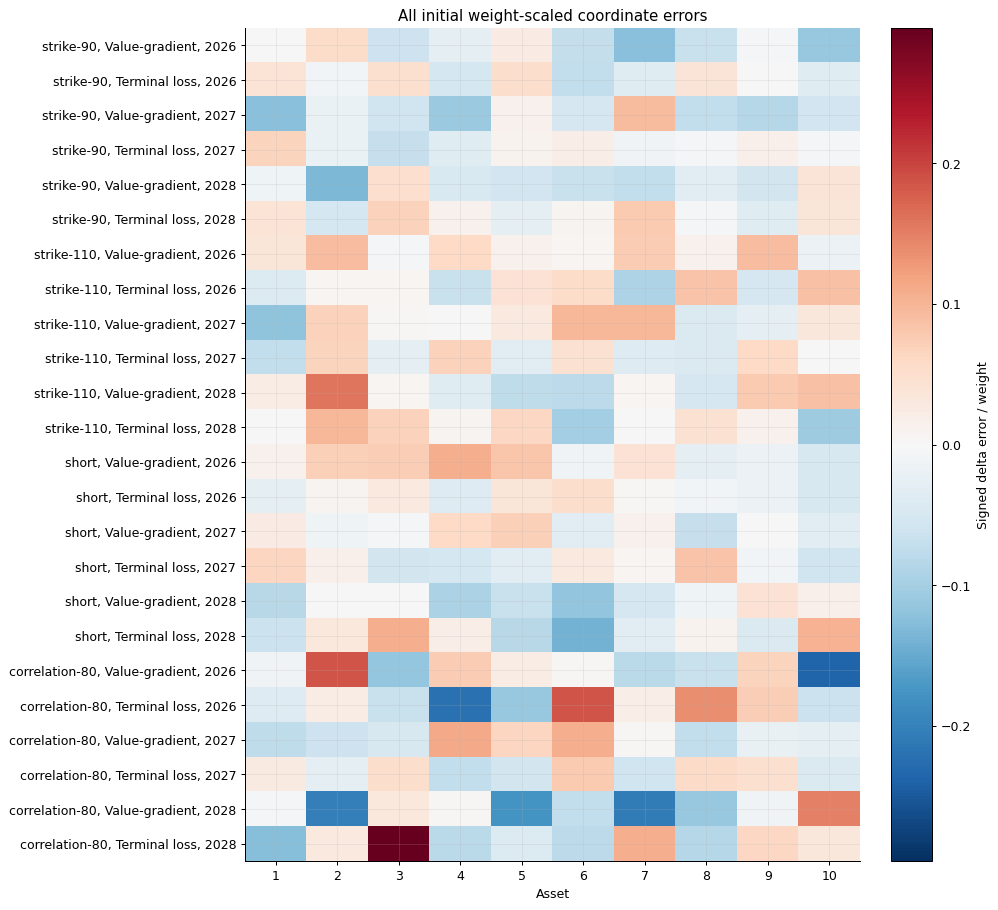

In [41]:
table(["Case","Seed","Model","Direction","Delta error","Error interval","Classification"], [
 [c["case"],r["seed"],development_names[k],name,d["signed_error"],d["signed_error_interval"],d["classification"]]
 for c in stress["cases"] if "result" in c["greeks"] for r in c["greeks"]["result"]["runs"] if "models" in r
 for k,m in r["models"].items() for name,d in m["directional_deltas"].items()])
if stress_models:
 errors=np.asarray([[d["signed_error"] for d in m["scaled_delta_checks"]] for i,c,r,k,m in stress_models])
 limit=max(0.01,float(np.max(np.abs(errors))))
 fig,ax=plt.subplots(figsize=(11,10),constrained_layout=True)
 shown=ax.imshow(errors,aspect="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)
 ax.set(xticks=range(10),xticklabels=range(1,11),xlabel="Asset",yticks=range(len(stress_models)),
        yticklabels=[f'{c["case"].replace("arithmetic-10-", "")}, {development_names[k]}, {r["seed"]}' for i,c,r,k,m in stress_models],
        title="All initial weight-scaled coordinate errors")
 fig.colorbar(shown,ax=ax,label="Signed delta error / weight")
 plt.show()


## 40. Selected curvature and asymmetric inputs

The value-gradient model supplies $v^\top H_uv$. Its own central delta secant verifies differentiation of the network, not model accuracy. The numerical arithmetic reference instead estimates

$$\Gamma_v^{(h)}=\frac{v^\top\Delta(s+hv)-v^\top\Delta(s-hv)}{2h}.$$

The plus/minus references use matched scrambles and an independent pilot for the geometric control. Intervals come from the paired scramble-level secants. Bumps 1, 0.5 and 0.1 are in physical spot units. These intervals describe sampling uncertainty around finite-bump quantities and exclude bump bias. Smaller bumps can amplify sampling noise near payoff kinks; no curvature target or preferred bump is selected after seeing results.

The existing five-asset geometric fits supply a separate asymmetric check with unequal spots, weights, volatilities, dividends and mixed-sign correlations. Their initial Hessian is checked against the analytical geometric-basket chain rule; their path deltas retain analytical references. They are one-seed fits from the earlier experiment, not additional stress retraining. The terminal solver has no global initial-price Hessian, so its curvature remains unavailable.


Case,Seed,Direction,Network gamma,"Reference secants (bump, estimate, SE)",Error intervals
arithmetic-10-strike-90,2026,coordinate_1,4.701814e-06,"[(1.0, 0.00017097530073340288, 3.30215950341915e-06), (0.5, 0.00017166042482306965, 4.9094443783488164e-06), (0.1, 0.00016575721962040074, 8.27014122755731e-06)]","[[-0.00017331187337863511, -0.00015923510063277783], [-0.00017742284408455583, -0.00015649437810619064], [-0.00017868279465389653, -0.00014342801713151213]]"
arithmetic-10-strike-90,2026,parallel,0.001431223,"[(1.0, 0.016477987041837023, 7.21513536041569e-05), (0.5, 0.016535967233356694, 0.00012284613363554894), (0.1, 0.016624178409655847, 0.00035828325407551636)]","[[-0.015200551281801903, -0.0148929773420997], [-0.015366584839181739, -0.014842904167759205], [-0.015956618358850563, -0.01442929300068869]]"
arithmetic-10-strike-90,2027,coordinate_1,5.444524e-05,"[(1.0, 0.00017097530073340288, 3.30215950341915e-06), (0.5, 0.00017166042482306965, 4.9094443783488164e-06), (0.1, 0.00016575721962040074, 8.27014122755731e-06)]","[[-0.00012356844672548273, -0.00010949167397962545], [-0.00012767941743140344, -0.00010675095145303826], [-0.00012893936800074414, -9.368459047835975e-05]]"
arithmetic-10-strike-90,2027,parallel,0.0005523044,"[(1.0, 0.016477987041837023, 7.21513536041569e-05), (0.5, 0.016535967233356694, 0.00012284613363554894), (0.1, 0.016624178409655847, 0.00035828325407551636)]","[[-0.016079469593425395, -0.01577189565372319], [-0.01624550315080523, -0.015721822479382697], [-0.016835536670474053, -0.015308211312312182]]"
arithmetic-10-strike-90,2028,coordinate_1,0.0001144232,"[(1.0, 0.00017097530073340288, 3.30215950341915e-06), (0.5, 0.00017166042482306965, 4.9094443783488164e-06), (0.1, 0.00016575721962040074, 8.27014122755731e-06)]","[[-6.35905060973941e-05, -4.951373335153682e-05], [-6.770147680331482e-05, -4.677301082494963e-05], [-6.896142737265551e-05, -3.370664985027112e-05]]"
arithmetic-10-strike-90,2028,parallel,-0.002120764,"[(1.0, 0.016477987041837023, 7.21513536041569e-05), (0.5, 0.016535967233356694, 0.00012284613363554894), (0.1, 0.016624178409655847, 0.00035828325407551636)]","[[-0.018752537867042722, -0.01844496392734052], [-0.018918571424422558, -0.018394890753000024], [-0.01950860494409138, -0.01798127958592951]]"
arithmetic-10-strike-110,2026,coordinate_1,0.0001783012,"[(1.0, 0.0002960065275471131, 5.245058938298173e-06), (0.5, 0.000299123857630527, 8.068159641187254e-06), (0.1, 0.0003063376499093319, 1.7875512143611947e-05)]","[[-0.00012888486457801365, -0.0001065257075970739], [-0.00013801949137166996, -0.0001036257409702454], [-0.00016613716068491252, -8.993565621461265e-05]]"
arithmetic-10-strike-110,2026,parallel,-0.0004885369,"[(1.0, 0.029252544901887535, 0.00013282242283533925), (0.5, 0.02926910181482397, 0.00024617227413522457), (0.1, 0.0291048587731812, 0.0005901160011544782)]","[[-0.030024186078476973, -0.029457977492891908], [-0.030282342480455818, -0.029232934916785934], [-0.03085119813946637, -0.028335593174489842]]"
arithmetic-10-strike-110,2027,coordinate_1,6.387275e-05,"[(1.0, 0.0002960065275471131, 5.245058938298173e-06), (0.5, 0.000299123857630527, 8.068159641187254e-06), (0.1, 0.0003063376499093319, 1.7875512143611947e-05)]","[[-0.0002433133590410594, -0.00022095420206011965], [-0.0002524479858347157, -0.00021805423543329116], [-0.00028056565514795827, -0.0002043641506776584]]"
arithmetic-10-strike-110,2027,parallel,0.002474225,"[(1.0, 0.029252544901887535, 0.00013282242283533925), (0.5, 0.02926910181482397, 0.00024617227413522457), (0.1, 0.0291048587731812, 0.0005901160011544782)]","[[-0.02706142410574789, -0.026495215520162825], [-0.02731958050772674, -0.026270172944056855], [-0.027888436166737286, -0.02537283120176076]]"


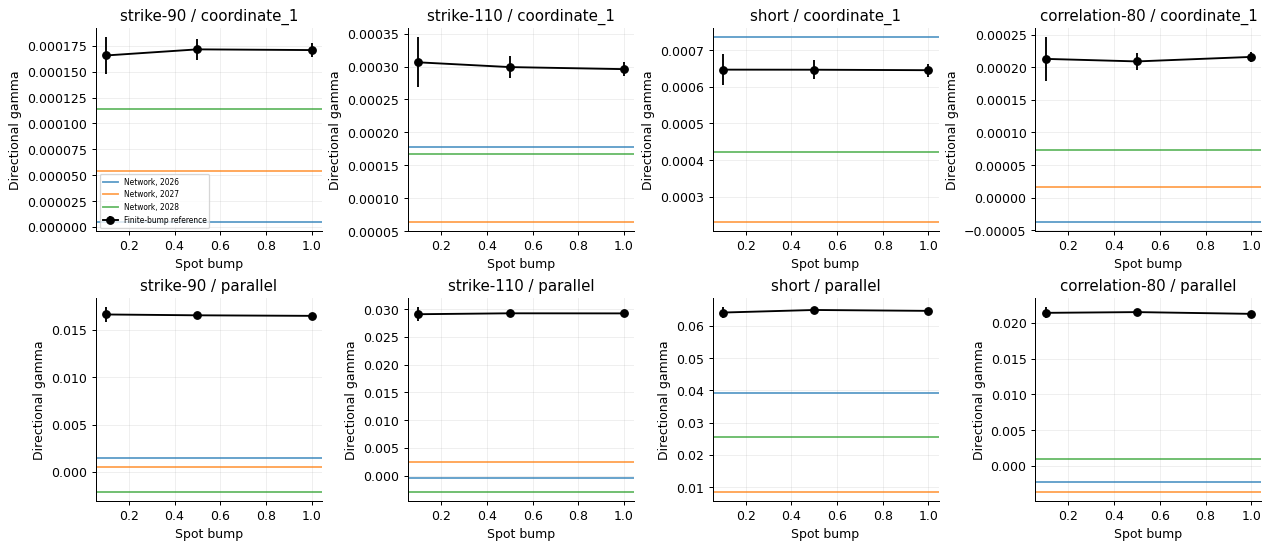

Asymmetric seed,Model,Price error,Scaled coordinate errors,Path delta RMSE
2026,Terminal loss,0.03089642,"[0.08621415837967696, 0.032182699035900875, 0.011142737164503216, 0.007682884338594098, -0.0057695594188456045]",0.0252498
2026,Value-gradient,0.2746429,"[0.010382877386080555, -0.06280652870769121, -0.10871985935554343, -0.022392678828792145, 0.006106327243387555]",0.02791369


Asymmetric seed,Direction,Network gamma,Exact gamma,Gamma error
2026,coordinate_1,-6.851201e-05,-0.0002340138,0.0001655018
2026,parallel,-0.005037159,0.02689721,-0.03193437


In [42]:
curvature_cases=[c for c in stress["cases"] if "result" in c["greeks"]]
table(["Case","Seed","Direction","Network gamma","Reference secants (bump, estimate, SE)","Error intervals"], [
 [c["case"],r["seed"],name,entry["gamma"],
 [(b["bump"],b["statistics"]["estimate"],b["statistics"]["standard_error"]) for b in c["greeks"]["result"]["curvature_reference"][name]["bumps"]],
 [b["signed_error_interval"] for b in entry["bump_checks"]]]
 for c in curvature_cases for r in c["greeks"]["result"]["runs"] if "value_gradient_curvature" in r
 for name,entry in r["value_gradient_curvature"].items()])
fig,axes=plt.subplots(2,len(stress["cases"]),figsize=(14,6),squeeze=False,constrained_layout=True)
for column,c in enumerate(stress["cases"]):
 if "result" not in c["greeks"]:continue
 diag=c["greeks"]["result"]
 for row,name in enumerate(diag["curvature_reference"]):
  ax=axes[row,column];ref=diag["curvature_reference"][name]
  xs=[b["bump"] for b in ref["bumps"]]
  ax.errorbar(xs,[b["statistics"]["estimate"] for b in ref["bumps"]],
    yerr=[0 if b["statistics"]["confidence_low"] is None else (b["statistics"]["confidence_high"]-b["statistics"]["confidence_low"])/2 for b in ref["bumps"]],
    color="black",marker="o",label="Finite-bump reference")
  for r,color in zip(diag["runs"],("tab:blue","tab:orange","tab:green")):
   if "value_gradient_curvature" in r:ax.axhline(r["value_gradient_curvature"][name]["gamma"],color=color,label=f'Network, {r["seed"]}',alpha=0.7)
  ax.set(title=f'{c["case"].replace("arithmetic-10-", "")} / {name}',xlabel="Spot bump",ylabel="Directional gamma")
axes[0,0].legend(fontsize=6)
plt.show()
asym=stress["asymmetric"].get("result")
if asym is not None:
 table(["Asymmetric seed","Model","Price error","Scaled coordinate errors","Path delta RMSE"], [
 [r["seed"],development_names[k],m["price_error"],[d["signed_error"] for d in m["scaled_delta_checks"]],
 r["analytical_path_risk"]["models"][k]["path_delta_rmse"]] for r in asym["runs"] if "models" in r for k,m in r["models"].items()])
 table(["Asymmetric seed","Direction","Network gamma","Exact gamma","Gamma error"], [
 [r["seed"],name,g["gamma"],asym["curvature_reference"][name]["exact_gamma"],g["exact_gamma_error"]]
 for r in asym["runs"] if "value_gradient_curvature" in r for name,g in r["value_gradient_curvature"].items()])


## 41. Stress-study resources and retained failures

The tables keep every scheduled fit and diagnostic task, including failed or capped tasks. Training, references and Greek diagnostics have separate worker guards. The saved terminal checkpoints do not provide initial gamma. Arithmetic conditional path references remain unavailable. Curvature is restricted to the two declared initial directions, and correlation 0.80 is not a singular-correlation limit.


In [43]:
table(["Case","Seed","Model","Status","Updates","Selected","Fit seconds","Worker peak MiB"], [
 [c["case"],r["seed"],development_names[k],t["status"],t.get("completed_updates"),t.get("selected_step"),
 t.get("training_seconds"),t.get("guard",{}).get("peak_resident_mib")]
 for c in stress["cases"] for r in c["study"]["runs"] for k,t in r["tasks"].items()])
table(["Case","Greek status","Diagnostic worker seconds","Diagnostic peak MiB"], [
 [c["case"],c["greeks"]["status"],c["greeks"].get("guard",{}).get("process_wall_seconds"),c["greeks"].get("guard",{}).get("peak_resident_mib")]
 for c in stress["cases"]]+[["Asymmetric geometric",stress["asymmetric"]["status"],stress["asymmetric"].get("guard",{}).get("process_wall_seconds"),
 stress["asymmetric"].get("guard",{}).get("peak_resident_mib")]])
table(["Study cost","Value"],[("Total wall seconds",stress["wall_seconds"]),
 ("Controller peak MiB",stress["controller_peak_resident_mib"])])


Case,Seed,Model,Status,Updates,Selected,Fit seconds,Worker peak MiB
arithmetic-10-strike-90,2026,Terminal loss,completed,3000,2800,24.91757,328.8594
arithmetic-10-strike-90,2026,Value-gradient,completed,3000,3000,15.66377,366.5898
arithmetic-10-strike-90,2027,Terminal loss,completed,3000,2400,25.15558,328.5977
arithmetic-10-strike-90,2027,Value-gradient,completed,3000,3000,16.55008,366.1055
arithmetic-10-strike-90,2028,Terminal loss,completed,3000,2900,25.99444,329.4883
arithmetic-10-strike-90,2028,Value-gradient,completed,3000,2900,15.81423,366.7227
arithmetic-10-strike-110,2026,Terminal loss,completed,3000,2900,23.25601,329.1953
arithmetic-10-strike-110,2026,Value-gradient,completed,3000,3000,16.43182,365.9648
arithmetic-10-strike-110,2027,Terminal loss,completed,3000,2200,24.64394,328.5742
arithmetic-10-strike-110,2027,Value-gradient,completed,3000,3000,15.44791,366.7812


Case,Greek status,Diagnostic worker seconds,Diagnostic peak MiB
arithmetic-10-strike-90,completed,9.817858,285.3477
arithmetic-10-strike-110,completed,9.43277,285.3516
arithmetic-10-short,completed,9.481648,285.3984
arithmetic-10-correlation-80,completed,9.582871,285.3594
Asymmetric geometric,completed,2.869811,311.9141


Study cost,Value
Total wall seconds,628.3312
Controller peak MiB,267.6914
